# Handwritten digit classification (MNIST subset, 8k images)

**Questions**
1. How do standard models perform on the flattened pixel data (baseline)?
2. What do feature extraction / dimensionality reduction (PCA, HOG, autoencoder codes) add?
3. How do the training paradigms compare: supervised, semi-supervised, unsupervised?

**Structure**

| section | content |
|---|---|
| 1. Data | load, clean, explore, split, scale |
| 2. Models | neural-network classes, autoencoder, feature extractors (definitions only) |
| 3. Training | 3.1 utils, then the experiments: 3.2 baselines (default hyperparameters), 3.3 feature extraction, 3.4 hyperparameter tuning, 3.5 training paradigms |
| 4. Metrics | 4.1 result tables, 4.2 plots |
| 5. Testing | final evaluation of the finalists on the held-out test split, error analysis |

**Note** All model *selection* uses 5-fold stratified CV on the training split. The test split is used only in
sections 3.5 (paradigm comparison; nothing is tuned on it) and 5 (finalists, evaluated once).

In [68]:
import copy
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from matplotlib.ticker import NullLocator
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report, confusion_matrix,
                             normalized_mutual_info_score, precision_recall_fscore_support, roc_curve, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.svm import SVC
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
DATA_PATH = Path('data') / 'data.csv'
SAVE_FIGS = True       # also write every figure to figures/<name>.png (200 dpi) for the report

plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'legend.fontsize': 9, 'figure.dpi': 110,
                     'savefig.dpi': 200, 'savefig.bbox': 'tight'})

# 1. Data

## 1.1 Loading and cleaning

In [2]:
column_names = ['label'] + [f'x{i}' for i in range(784)]
data = pd.read_csv(DATA_PATH, header=None, names=column_names)
print('raw shape:', data.shape)

raw shape: (8043, 785)


In [3]:
# Cleaning
bad = data[data.isna().any(axis=1)]
print(f'{len(bad)} row(s) with missing pixels at index {bad.index.tolist()} '
      f'({bad.isna().sum(axis=1).tolist()} of 784 pixels missing); last line of file: {bad.index.tolist() == [len(data) - 1]}')
data = data.dropna().reset_index(drop=True)

pixels = data.drop(columns='label').to_numpy()
assert pixels.shape[1] == 784
print('labels:', sorted(data['label'].unique().tolist()))
print('pixel range:', pixels.min(), '-', pixels.max())
print('blank images:', int((pixels.sum(1) == 0).sum()))
print('duplicate rows:', int(data.duplicated().sum()))

1 row(s) with missing pixels at index [8042] ([409] of 784 pixels missing); last line of file: True
labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pixel range: 0.0 - 255.0
blank images: 0
duplicate rows: 0


## 1.2 Exploratory analysis

8042 images
sparsity (zero pixels): 0.810 | avg. non-zero pixels per image: 149 of 784 | pixels that are 0 in every image: 120


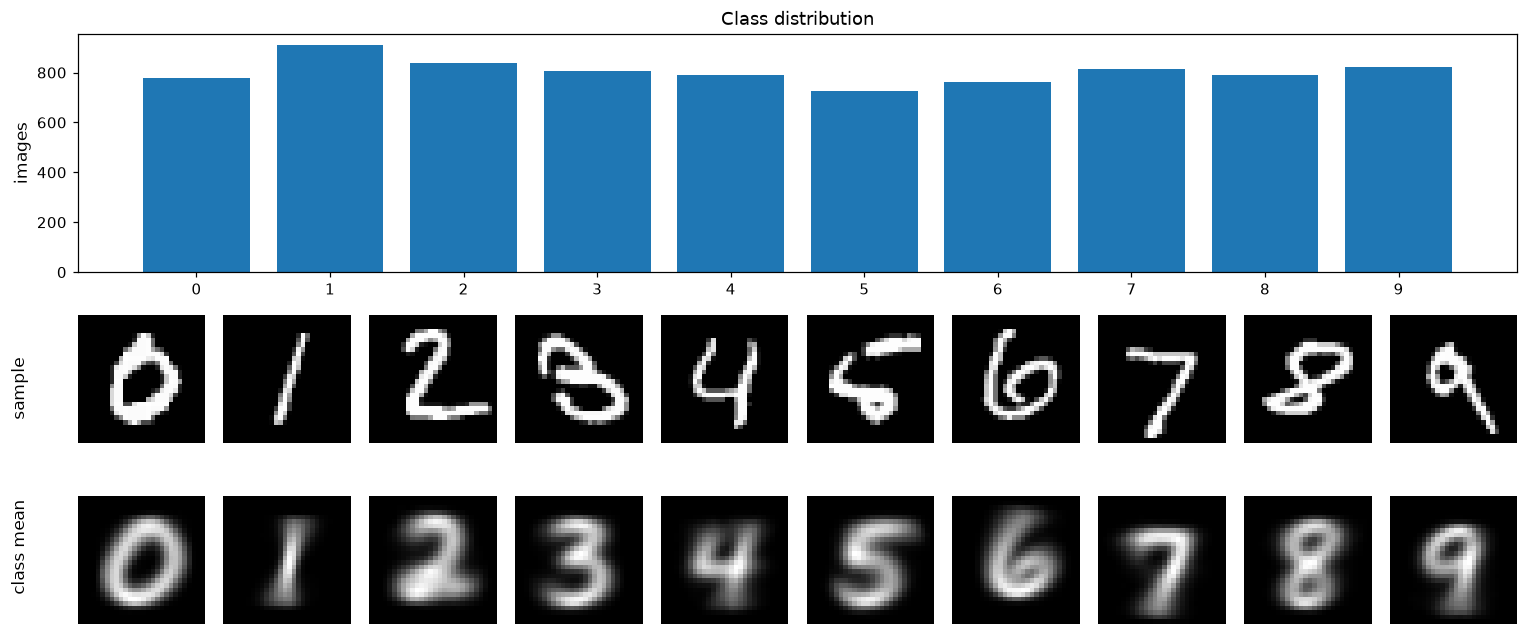

In [4]:
# Class balance, sparsity, example digits and class-mean images
labels = data['label'].to_numpy()
pix = pixels.astype(np.float32)
print(f'{len(data)} images')
print(f'sparsity (zero pixels): {(pix == 0).mean():.3f} | '
      f'avg. non-zero pixels per image: {(pix > 0).sum(1).mean():.0f} of 784 | '
      f'pixels that are 0 in every image: {int((pix.max(0) == 0).sum())}')

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(3, 10, height_ratios=[1.6, 1, 1])
ax = fig.add_subplot(gs[0, :])
counts = pd.Series(labels).value_counts().sort_index()
ax.bar(counts.index, counts.values); ax.set_xticks(range(10))
ax.set_title('Class distribution'); ax.set_ylabel('images')
for d in range(10):
    idx = np.where(labels == d)[0]
    a = fig.add_subplot(gs[1, d]); a.imshow(pix[idx[0]].reshape(28, 28), cmap='gray'); a.axis('off')
    b = fig.add_subplot(gs[2, d]); b.imshow(pix[idx].mean(0).reshape(28, 28), cmap='gray'); b.axis('off')
fig.text(0.01, 0.40, 'sample', rotation=90, va='center'); fig.text(0.01, 0.16, 'class mean', rotation=90, va='center')
plt.tight_layout()
if SAVE_FIGS:
    Path('figures').mkdir(exist_ok=True); fig.savefig('figures/eda.png')
plt.show()

## 1.3 Split and scaling

In [5]:
# Stratified 80/20 split; pixels scaled to [0, 1]
x_all = pix / 255.0
y_all = labels.astype(np.int64)
train_idx, test_idx = next(StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(x_all, y_all))
x_train, y_train = x_all[train_idx], y_all[train_idx]
x_test,  y_test  = x_all[test_idx],  y_all[test_idx]

train_hashes = {r.tobytes() for r in x_train}
print(f'train {x_train.shape}, test {x_test.shape}; test images also present in train: '
      f'{sum(r.tobytes() in train_hashes for r in x_test)}')

train (6433, 784), test (1609, 784); test images also present in train: 0


# 2. Models

The classical models (logistic regression, kNN, RBF-SVM, random forest) come straight from scikit-learn and are instantiated in section 3: first with default hyperparameters, then tuned in 3.4.

## 2.1 Neural-network base class (mini-batch training, early stopping)

In [6]:
def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


def get_default_device():
    return torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')


def _as_tensor(a, dtype):
    if isinstance(a, torch.Tensor):
        return a.to(dtype)
    return torch.as_tensor(np.asarray(a), dtype=dtype)


class BaseNN(nn.Module):
    """Mini-batch training, early stopping on a validation set, batched inference."""

    def __init__(self, device=None):
        super().__init__()
        self.device = device or get_default_device()
        self.loss = nn.CrossEntropyLoss()
        self.optimizer = None                 # created by subclasses once the parameters exist

    def forward(self, X):
        raise NotImplementedError

    @torch.no_grad()
    def _logits(self, X, batch_size=1024):
        self.eval()
        X = _as_tensor(X, torch.float32)
        return torch.cat([self.forward(X[i:i + batch_size].to(self.device)).cpu()
                          for i in range(0, len(X), batch_size)])

    def predict(self, X, batch_size=1024):
        return self._logits(X, batch_size).argmax(-1).numpy()

    def predict_proba(self, X, batch_size=1024):
        return torch.softmax(self._logits(X, batch_size), dim=-1).numpy()

    def fit(self, X, Y, X_val=None, Y_val=None, epochs=50, batch_size=64,
            patience=5, seed=None, verbose=True):
        """Every epoch: reshuffle, split into mini-batches, one optimizer step per batch.
        With a validation set: keep the weights of the best validation accuracy and stop after
        `patience` epochs without improvement. Returns per-epoch train/val loss and accuracy."""
        if seed is not None:
            torch.manual_seed(seed)
            np.random.seed(seed)
        X = _as_tensor(X, torch.float32)
        Y = _as_tensor(Y, torch.long)
        g = torch.Generator()
        g.manual_seed(seed if seed is not None else 0)
        loader = DataLoader(TensorDataset(X, Y), batch_size=batch_size, shuffle=True, generator=g,
                            drop_last=(len(X) % batch_size == 1))   # BatchNorm cannot train on a batch of 1

        use_val = X_val is not None and Y_val is not None
        if use_val:
            Xv = _as_tensor(X_val, torch.float32)
            Yv = _as_tensor(Y_val, torch.long)

        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
        best_acc, best_state, wait = -1.0, None, 0

        for epoch in range(epochs):
            self.train()
            running_loss, correct, n = 0.0, 0, 0
            for xb, yb in loader:
                xb, yb = xb.to(self.device), yb.to(self.device)
                self.optimizer.zero_grad()
                logits = self.forward(xb)
                loss = self.loss(logits, yb)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * len(xb)
                correct += (logits.argmax(-1) == yb).sum().item()
                n += len(xb)
            history['train_loss'].append(running_loss / n)
            history['train_acc'].append(correct / n)
            msg = (f"epoch {epoch + 1:3d}/{epochs}  loss {history['train_loss'][-1]:.4f}  "
                   f"acc {history['train_acc'][-1]:.4f}")

            if use_val:
                logits_v = self._logits(Xv)
                v_loss = self.loss(logits_v, Yv).item()
                v_acc = (logits_v.argmax(-1) == Yv).float().mean().item()
                history['val_loss'].append(v_loss)
                history['val_acc'].append(v_acc)
                msg += f"  | val loss {v_loss:.4f}  val acc {v_acc:.4f}"
                if v_acc > best_acc:
                    best_acc, wait = v_acc, 0
                    best_state = copy.deepcopy(self.state_dict())
                else:
                    wait += 1
                    if wait >= patience:
                        if verbose:
                            print(msg)
                            print(f'Early stopping at epoch {epoch + 1} (best val acc {best_acc:.4f})')
                        break
            if verbose:
                print(msg)

        if best_state is not None:
            self.load_state_dict(best_state)
        return history

## 2.2 Supervised networks

`CNN.forward` reshapes the flat `(N, 784)` input to `(N, 1, 28, 28)` with `X.view(-1, 1, 28, 28)`, so the convolutions see the 2D image.

In [7]:
class MLP(BaseNN):
    """784 -> 512 -> 256 -> 128 -> 10 with dropout."""

    def __init__(self, hidden=(512, 256, 128), p=0.3, lr=1e-3, weight_decay=1e-4, device=None):
        super().__init__(device)
        layers, d_in = [], 784
        for h in hidden:
            layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(p)]
            d_in = h
        layers.append(nn.Linear(d_in, 10))
        self.layers = nn.Sequential(*layers)
        self.to(self.device)
        self.optimizer = optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)

    def forward(self, X):
        return self.layers(X)


class CNN(BaseNN):
    """Two conv blocks + dense head. Takes flat 784-dim input and reshapes it to (N, 1, 28, 28)."""

    def __init__(self, p=0.3, lr=1e-3, weight_decay=1e-4, device=None):
        super().__init__(device)
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 x 14 x 14
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 x 7 x 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(p), nn.Linear(32 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p), nn.Linear(128, 10),
        )
        self.to(self.device)
        self.optimizer = optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)

    def forward(self, X):
        return self.classifier(self.features(X.view(-1, 1, 28, 28)))

## 2.3 Autoencoder and semi-supervised network

In [8]:
class DeepEncoder(nn.Module):
    def __init__(self, latent_dim=64, p=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(p),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(p),
            nn.Linear(256, latent_dim), nn.BatchNorm1d(latent_dim), nn.ReLU(),
        )

    def forward(self, x):
        return self.net(x)


class DeepDecoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Linear(256, 512), nn.BatchNorm1d(512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),               # pixels are scaled to [0, 1]
        )

    def forward(self, z):
        return self.net(z)


class Autoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = DeepEncoder(latent_dim)
        self.decoder = DeepDecoder(latent_dim)

    def forward(self, x):
        return self.decoder(self.encoder(x))


class SemiSupervisedClassifier(BaseNN):
    """encoder (pretrained or randomly initialised) + classification head, same API as the other NNs."""

    def __init__(self, encoder, latent_dim=64, freeze_encoder=False, p=0.3,
                 lr=1e-3, weight_decay=1e-4, device=None):
        super().__init__(device)
        self.encoder = encoder
        self.freeze_encoder = freeze_encoder
        if freeze_encoder:
            for prm in self.encoder.parameters():
                prm.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p),
            nn.Linear(128, 10),
        )
        self.to(self.device)
        self.optimizer = optim.Adam([q for q in self.parameters() if q.requires_grad],
                                    lr=lr, weight_decay=weight_decay)

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_encoder:        # frozen means frozen: no BatchNorm statistic updates, no dropout
            self.encoder.eval()
        return self

    def forward(self, X):
        return self.head(self.encoder(X))

In [9]:
@torch.no_grad()
def encode(encoder, X, batch_size=1024):
    """Latent codes (numpy) for images X."""
    encoder.eval()
    dev = next(encoder.parameters()).device
    X = torch.as_tensor(X, dtype=torch.float32)
    return torch.cat([encoder(X[i:i + batch_size].to(dev)).cpu()
                      for i in range(0, len(X), batch_size)]).numpy()


@torch.no_grad()
def reconstruct(ae, X, batch_size=1024):
    """Autoencoder reconstructions (numpy) of images X."""
    ae.eval()
    dev = next(ae.parameters()).device
    X = torch.as_tensor(X, dtype=torch.float32)
    return torch.cat([ae(X[i:i + batch_size].to(dev)).cpu()
                      for i in range(0, len(X), batch_size)]).numpy()

## 2.4 Feature extractors for scikit-learn pipelines

In [10]:
class HOG(BaseEstimator, TransformerMixin):
    """Histogram of oriented gradients for flattened 28x28 images (stateless)."""

    def __init__(self, pixels_per_cell=4, orientations=9, cells_per_block=2):
        self.pixels_per_cell = pixels_per_cell
        self.orientations = orientations
        self.cells_per_block = cells_per_block

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        try:
            from skimage.feature import hog
        except ImportError as e:
            raise ImportError('HOG features need scikit-image:  pip install scikit-image') from e
        X = np.asarray(X)
        return np.array([hog(img.reshape(28, 28), orientations=self.orientations,
                             pixels_per_cell=(self.pixels_per_cell,) * 2,
                             cells_per_block=(self.cells_per_block,) * 2, block_norm='L2-Hys')
                         for img in X], dtype=np.float32)


class AEFeatures(BaseEstimator, TransformerMixin):
    """Latent codes of a pretrained autoencoder's encoder. encode_fn(encoder, X) -> numpy array."""

    def __init__(self, encoder, encode_fn):
        self.encoder = encoder
        self.encode_fn = encode_fn

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return self.encode_fn(self.encoder, X)

    def parameters(self):              # lets count_params() see the encoder weights
        return self.encoder.parameters()

# 3. Training

## 3.1 Utils

`evaluate` scores a set of predictions; it sits here because every training loop below calls it.

In [11]:
def evaluate(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred),
            'macro_precision': p, 'macro_recall': r, 'macro_f1': f1}


def cross_validate(name, make_model, X, y, kind='sklearn', n_splits=5, seed=42,
                   fit_kwargs=None, inner_val_frac=0.15, verbose=True):
    """Stratified k-fold CV for one model.

    * Same seed => same folds for every model, so results are paired.
    * make_model must return a FRESH unfitted model (nothing carries over between folds).
    * kind='nn': early stopping uses an inner split of the fold's TRAINING part, never the held-out fold.
    """
    X, y = np.asarray(X), np.asarray(y)
    fit_kwargs = dict(fit_kwargs or {})
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    rows, histories = [], []
    oof_pred = np.full(len(y), -1, dtype=int)
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
        X_tr, y_tr, X_te, y_te = X[tr_idx], y[tr_idx], X[te_idx], y[te_idx]
        model = make_model()
        t0 = time.time()
        if kind == 'nn':
            X_fit, X_val, y_fit, y_val = train_test_split(
                X_tr, y_tr, test_size=inner_val_frac, stratify=y_tr, random_state=seed + fold)
            histories.append(model.fit(X_fit, y_fit, X_val, y_val,
                                       seed=seed + fold, verbose=False, **fit_kwargs))
        else:
            model.fit(X_tr, y_tr)
        fit_time = time.time() - t0

        y_pred = np.asarray(model.predict(X_te))
        oof_pred[te_idx] = y_pred
        m = evaluate(y_te, y_pred)
        m.update(fold=fold, fit_time_s=fit_time)
        rows.append(m)
        if verbose:
            print(f"[{name}] fold {fold}/{n_splits}: acc={m['accuracy']:.4f}  "
                  f"macroF1={m['macro_f1']:.4f}  ({fit_time:.1f}s)")
    return {'name': name, 'folds': pd.DataFrame(rows).set_index('fold'),
            'oof_pred': oof_pred, 'y_true': y, 'histories': histories}


def run_all(specs, X, y, n_splits=5, seed=42):
    """specs: name -> dict(make_model=callable, kind='sklearn'|'nn', fit_kwargs=dict)."""
    return {name: cross_validate(name, s['make_model'], X, y, kind=s.get('kind', 'sklearn'),
                                 n_splits=n_splits, seed=seed, fit_kwargs=s.get('fit_kwargs'))
            for name, s in specs.items()}


def sweep(make_fn, values, X, y, label, seed=42, n_splits=5):
    """CV accuracy for each hyperparameter value (same folds for all values)."""
    rows = []
    for v in values:
        res = cross_validate(f'{label}={v}', lambda v=v: make_fn(v), X, y, seed=seed,
                             n_splits=n_splits, verbose=False)
        f = res['folds']
        rows.append({'value': v, 'acc_mean': f['accuracy'].mean(), 'acc_std': f['accuracy'].std(),
                     'fit_time_s': f['fit_time_s'].mean()})
        print(f"{label}={v}: acc {rows[-1]['acc_mean']:.4f} ± {rows[-1]['acc_std']:.4f}")
    return pd.DataFrame(rows).set_index('value')

In [12]:
def stratified_subset(y, frac, seed):
    if frac >= 1.0:
        return np.arange(len(y))
    idx, _ = train_test_split(np.arange(len(y)), train_size=frac, stratify=y, random_state=seed)
    return idx


def run_label_sweep(x_train, y_train, x_test, y_test, label_fracs, seeds, nn_variants, references,
                    fit_kwargs, seed_fn=None, inner_val_frac=0.15):
    """For each label fraction and seed, train every variant on the same labeled subset.

    nn_variants : name -> zero-arg factory returning a fresh NN (fit/predict API of BaseNN)
    references  : name -> zero-arg factory returning a fresh sklearn estimator
    The early-stopping split for the NNs comes from the labeled subset itself (no other labels exist).
    The sklearn references use all labels of the subset.
    """
    rows = []
    for frac in label_fracs:
        for seed in seeds:
            idx = stratified_subset(y_train, frac, seed)
            X_l, y_l = x_train[idx], y_train[idx]
            n_val = max(10, int(round(inner_val_frac * len(idx))))      # at least one validation image per class
            X_fit, X_val, y_fit, y_val = train_test_split(
                X_l, y_l, test_size=n_val, stratify=y_l, random_state=seed)
            base = {'label_frac': frac, 'n_labels': len(idx), 'seed': seed}
            for name, make in nn_variants.items():
                if seed_fn is not None:
                    seed_fn(seed)
                model = make()
                model.fit(X_fit, y_fit, X_val, y_val, seed=seed, verbose=False, **fit_kwargs)
                rows.append({**base, 'method': name, **evaluate(y_test, model.predict(x_test))})
            for name, make in references.items():
                model = make().fit(X_l, y_l)
                rows.append({**base, 'method': name, **evaluate(y_test, model.predict(x_test))})
            print(f'done: {len(idx)} labels ({frac:.0%}), seed {seed}')
    return pd.DataFrame(rows)

In [13]:
def kmeans_cluster_eval(Z_train, y_train, Z_test, y_test, n_clusters=10, seed=42, n_init=10):
    """k-means on Z_train; each cluster gets the majority label of its TRAINING members.
    Reports test accuracy / macro-F1 (needs that label mapping) and NMI / ARI (label-free)."""
    km = KMeans(n_clusters=n_clusters, n_init=n_init, random_state=seed).fit(Z_train)
    mapping = {c: int(np.bincount(y_train[km.labels_ == c], minlength=10).argmax())
               for c in range(n_clusters)}
    clusters_test = km.predict(Z_test)
    y_pred = np.array([mapping[c] for c in clusters_test])
    return {**evaluate(y_test, y_pred),
            'NMI': normalized_mutual_info_score(y_test, clusters_test),
            'ARI': adjusted_rand_score(y_test, clusters_test)}

In [14]:
def train_autoencoder(x_unlabeled, latent_dim=64, epochs=25, batch_size=64, lr=1e-3,
                      weight_decay=1e-5, seed=42, verbose=True):
    """Train on images only (no labels). Returns (autoencoder in eval mode, per-epoch MSE list)."""
    device = get_default_device()
    torch.manual_seed(seed)
    ae = Autoencoder(latent_dim).to(device)
    X = torch.as_tensor(x_unlabeled, dtype=torch.float32)
    loader = DataLoader(TensorDataset(X), batch_size=batch_size, shuffle=True,
                        drop_last=(len(X) % batch_size == 1))
    opt = optim.Adam(ae.parameters(), lr=lr, weight_decay=weight_decay)
    crit = nn.MSELoss()
    history = []
    for epoch in range(epochs):
        ae.train()
        total = 0.0
        for (bx,) in loader:
            bx = bx.to(device)
            opt.zero_grad()
            loss = crit(ae(bx), bx)
            loss.backward()
            opt.step()
            total += loss.item() * len(bx)
        history.append(total / len(X))
        if verbose and (epoch == 0 or (epoch + 1) % 5 == 0):
            print(f'epoch {epoch + 1:2d}/{epochs}  reconstruction MSE {history[-1]:.5f}')
    return ae.eval(), history

## 3.2 Baselines on the flattened pixels

All models start with **default hyperparameters** (scikit-learn defaults: kNN with k=5, SVM with C=1). Tuning comes in 3.4, after the feature-extraction variants exist. Every model is cross-validated on the same 5 folds.

In [15]:
nn_fit = dict(epochs=50, batch_size=64, patience=5)       # early stopping on an inner validation split

baseline_specs = {
    'LogReg': dict(make_model=lambda: LogisticRegression(max_iter=1000), kind='sklearn'),
    'kNN': dict(make_model=lambda: KNeighborsClassifier(n_neighbors=5), kind='sklearn'),
    'SVM (RBF)': dict(make_model=lambda: SVC(kernel='rbf', C=1.0, gamma='scale'), kind='sklearn'),
    'Random Forest': dict(make_model=lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), kind='sklearn'),
    'MLP': dict(make_model=lambda: MLP(), kind='nn', fit_kwargs=nn_fit),
    'CNN': dict(make_model=lambda: CNN(), kind='nn', fit_kwargs=nn_fit),
}
baseline_cv = run_all(baseline_specs, x_train, y_train, n_splits=5, seed=SEED)

[LogReg] fold 1/5: acc=0.8974  macroF1=0.8956  (2.0s)
[LogReg] fold 2/5: acc=0.8936  macroF1=0.8924  (1.0s)
[LogReg] fold 3/5: acc=0.8943  macroF1=0.8927  (1.3s)
[LogReg] fold 4/5: acc=0.8997  macroF1=0.8984  (0.9s)
[LogReg] fold 5/5: acc=0.8896  macroF1=0.8889  (0.9s)
[kNN] fold 1/5: acc=0.9394  macroF1=0.9394  (0.0s)
[kNN] fold 2/5: acc=0.9262  macroF1=0.9264  (0.0s)
[kNN] fold 3/5: acc=0.9355  macroF1=0.9355  (0.0s)
[kNN] fold 4/5: acc=0.9386  macroF1=0.9385  (0.0s)
[kNN] fold 5/5: acc=0.9347  macroF1=0.9352  (0.0s)
[SVM (RBF)] fold 1/5: acc=0.9580  macroF1=0.9577  (1.8s)
[SVM (RBF)] fold 2/5: acc=0.9549  macroF1=0.9546  (1.7s)
[SVM (RBF)] fold 3/5: acc=0.9534  macroF1=0.9530  (1.7s)
[SVM (RBF)] fold 4/5: acc=0.9557  macroF1=0.9551  (1.6s)
[SVM (RBF)] fold 5/5: acc=0.9541  macroF1=0.9543  (1.7s)
[Random Forest] fold 1/5: acc=0.9464  macroF1=0.9456  (1.0s)
[Random Forest] fold 2/5: acc=0.9448  macroF1=0.9445  (1.0s)
[Random Forest] fold 3/5: acc=0.9464  macroF1=0.9461  (1.0s)
[Random

## 3.3 Feature extraction and dimensionality reduction

**Do we need dimensionality reduction?** Principal components of the training images: how many are needed to describe the data?

In [16]:
pca_full = PCA(random_state=SEED).fit(x_train)       # unsupervised, descriptive
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95 = [int(np.searchsorted(cum, t) + 1) for t in (0.90, 0.95)]
print(f'Components for 90% / 95% of the variance: {n90} / {n95} (of 784)')

Components for 90% / 95% of the variance: 84 / 147 (of 784)


**Unsupervised representation:** a deep autoencoder trained on the training images *without labels* (also used for the semi-supervised experiment in 3.5).

In [17]:
latent_dim = 64
ae, ae_history = train_autoencoder(x_train, latent_dim=latent_dim, seed=SEED)

recon = reconstruct(ae, x_test)
print(f'test reconstruction MSE: {((recon - x_test) ** 2).mean():.5f}')

epoch  1/25  reconstruction MSE 0.04931
epoch  5/25  reconstruction MSE 0.01962
epoch 10/25  reconstruction MSE 0.01632
epoch 15/25  reconstruction MSE 0.01498
epoch 20/25  reconstruction MSE 0.01424
epoch 25/25  reconstruction MSE 0.01378
test reconstruction MSE: 0.01154


**Same classifier (SVM, default hyperparameters), different representations.** Every extractor is a pipeline step,
so it is re-fitted on each fold's training part only. Initial settings: 50 PCA components, HOG with 4x4-pixel cells,
64-dimensional autoencoder codes. The autoencoder saw the unlabeled training images (including the held-out fold's
images, but never any labels).

In [18]:
pca_default = 50                                      # initial choice, tuned in 3.4
svm_default = lambda: SVC(kernel='rbf', C=1.0, gamma='scale')
feat_specs = {
    f'PCA-{pca_default} + SVM': dict(make_model=lambda: make_pipeline(PCA(n_components=pca_default, random_state=SEED), svm_default()), kind='sklearn'),
    'HOG + SVM': dict(make_model=lambda: make_pipeline(HOG(pixels_per_cell=4), svm_default()), kind='sklearn'),
    'AE codes + SVM': dict(make_model=lambda: make_pipeline(AEFeatures(ae.encoder, encode), svm_default()), kind='sklearn'),
}
feat_cv_svm = run_all(feat_specs, x_train, y_train, n_splits=5, seed=SEED)

# raw pixels + SVM is exactly the baseline SVM
feature_cv_svm = {'Raw pixels + SVM': baseline_cv['SVM (RBF)'], **feat_cv_svm}

[PCA-50 + SVM] fold 1/5: acc=0.9713  macroF1=0.9711  (0.5s)
[PCA-50 + SVM] fold 2/5: acc=0.9604  macroF1=0.9602  (0.5s)
[PCA-50 + SVM] fold 3/5: acc=0.9611  macroF1=0.9611  (0.4s)
[PCA-50 + SVM] fold 4/5: acc=0.9611  macroF1=0.9605  (0.4s)
[PCA-50 + SVM] fold 5/5: acc=0.9635  macroF1=0.9637  (0.4s)
[HOG + SVM] fold 1/5: acc=0.9767  macroF1=0.9766  (6.7s)
[HOG + SVM] fold 2/5: acc=0.9806  macroF1=0.9807  (7.1s)
[HOG + SVM] fold 3/5: acc=0.9782  macroF1=0.9782  (7.3s)
[HOG + SVM] fold 4/5: acc=0.9844  macroF1=0.9843  (6.1s)
[HOG + SVM] fold 5/5: acc=0.9759  macroF1=0.9760  (5.8s)
[AE codes + SVM] fold 1/5: acc=0.9674  macroF1=0.9673  (0.4s)
[AE codes + SVM] fold 2/5: acc=0.9619  macroF1=0.9618  (0.4s)
[AE codes + SVM] fold 3/5: acc=0.9658  macroF1=0.9659  (0.4s)
[AE codes + SVM] fold 4/5: acc=0.9666  macroF1=0.9661  (0.4s)
[AE codes + SVM] fold 5/5: acc=0.9627  macroF1=0.9626  (0.4s)


In [19]:
pca_default = 50                                      # initial choice, tuned in 3.4
knn_default = lambda: KNeighborsClassifier(n_neighbors=5)
feat_specs = {
    f'PCA-{pca_default} + kNN': dict(make_model=lambda: make_pipeline(PCA(n_components=pca_default, random_state=SEED), knn_default()), kind='sklearn'),
    'HOG + kNN': dict(make_model=lambda: make_pipeline(HOG(pixels_per_cell=4), knn_default()), kind='sklearn'),
    'AE codes + kNN': dict(make_model=lambda: make_pipeline(AEFeatures(ae.encoder, encode), knn_default()), kind='sklearn'),
}
feat_cv_knn = run_all(feat_specs, x_train, y_train, n_splits=5, seed=SEED)

# raw pixels + kNN is exactly the baseline kNN
feature_cv_knn = {'Raw pixels + kNN': baseline_cv['kNN'], **feat_cv_knn}

[PCA-50 + kNN] fold 1/5: acc=0.9479  macroF1=0.9477  (0.1s)
[PCA-50 + kNN] fold 2/5: acc=0.9394  macroF1=0.9393  (0.1s)
[PCA-50 + kNN] fold 3/5: acc=0.9479  macroF1=0.9477  (0.1s)
[PCA-50 + kNN] fold 4/5: acc=0.9479  macroF1=0.9476  (0.1s)
[PCA-50 + kNN] fold 5/5: acc=0.9495  macroF1=0.9495  (0.1s)
[HOG + kNN] fold 1/5: acc=0.9456  macroF1=0.9456  (2.3s)
[HOG + kNN] fold 2/5: acc=0.9495  macroF1=0.9497  (2.4s)
[HOG + kNN] fold 3/5: acc=0.9456  macroF1=0.9462  (2.5s)
[HOG + kNN] fold 4/5: acc=0.9611  macroF1=0.9613  (2.6s)
[HOG + kNN] fold 5/5: acc=0.9533  macroF1=0.9534  (2.8s)
[AE codes + kNN] fold 1/5: acc=0.9573  macroF1=0.9570  (0.1s)
[AE codes + kNN] fold 2/5: acc=0.9472  macroF1=0.9469  (0.1s)
[AE codes + kNN] fold 3/5: acc=0.9479  macroF1=0.9475  (0.1s)
[AE codes + kNN] fold 4/5: acc=0.9635  macroF1=0.9630  (0.1s)
[AE codes + kNN] fold 5/5: acc=0.9487  macroF1=0.9486  (0.1s)


In [20]:
feature_cv = {**feature_cv_svm, **feature_cv_knn}
feat_cv = {**feat_cv_svm, **feat_cv_knn}

## 3.4 Hyperparameter tuning

Now that the baselines and the feature pipelines exist, tune with the same 5-fold CV on the training split:
kNN's `k` and the SVM's `C` on raw pixels, then the number of PCA components (with the tuned `C`).
The tuned `C` is then reused for all SVM pipelines (`gamma='scale'` adapts the RBF width to each feature space),
and the tuned variants are cross-validated again, so the effect of tuning can be read off directly.

In [21]:
knn_sweep = sweep(lambda k: KNeighborsClassifier(n_neighbors=k), [1, 3, 5, 7, 11, 15], x_train, y_train, 'k', seed=SEED)
svm_sweep = sweep(lambda C: SVC(kernel='rbf', C=C, gamma='scale'), [0.5, 1, 2, 5, 10, 20, 50], x_train, y_train, 'C', seed=SEED)
best_k = int(knn_sweep['acc_mean'].idxmax())
best_C = float(svm_sweep['acc_mean'].idxmax())
print(f'selected: k={best_k}, C={best_C:g}   (differences below one std are ties; prefer the simpler setting)')

k=1: acc 0.9361 ± 0.0070
k=3: acc 0.9367 ± 0.0065
k=5: acc 0.9349 ± 0.0052
k=7: acc 0.9363 ± 0.0042
k=11: acc 0.9293 ± 0.0027
k=15: acc 0.9248 ± 0.0047
C=0.5: acc 0.9476 ± 0.0036
C=1: acc 0.9552 ± 0.0018
C=2: acc 0.9596 ± 0.0034
C=5: acc 0.9602 ± 0.0054
C=10: acc 0.9602 ± 0.0047
C=20: acc 0.9600 ± 0.0049
C=50: acc 0.9600 ± 0.0049
selected: k=3, C=5   (differences below one std are ties; prefer the simpler setting)


In [22]:
pca_sweep = sweep(
    lambda n: make_pipeline(PCA(n_components=n, random_state=SEED), SVC(C=best_C, gamma='scale')),
    [10, 20, 30, 50, 100, 150], x_train, y_train, 'PCA components', 
    seed=SEED
)
best_ncomp = int(pca_sweep['acc_mean'].idxmax())
print(f'selected: {best_ncomp} PCA components')

PCA components=10: acc 0.9246 ± 0.0052
PCA components=20: acc 0.9624 ± 0.0030
PCA components=30: acc 0.9658 ± 0.0034
PCA components=50: acc 0.9681 ± 0.0041
PCA components=100: acc 0.9649 ± 0.0042
PCA components=150: acc 0.9641 ± 0.0041
selected: 50 PCA components


In [23]:
pca_tuned_name_svm = f'PCA-{best_ncomp} + SVM (tuned)'
pca_tuned_name_knn = f'PCA-{best_ncomp} + kNN (tuned)'

tuned_svm = lambda: SVC(kernel='rbf', C=best_C, gamma='scale')
tuned_knn = lambda: KNeighborsClassifier(n_neighbors=best_k)

tuned_specs = {
    'kNN (tuned)': dict(make_model=tuned_knn, kind='sklearn'),
    'SVM (tuned)': dict(make_model=tuned_svm, kind='sklearn'),

    pca_tuned_name_knn: dict(make_model=lambda: make_pipeline(PCA(n_components=best_ncomp, random_state=SEED), tuned_knn()), kind='sklearn'),
    'AE codes + kNN (tuned)': dict(make_model=lambda: make_pipeline(AEFeatures(ae.encoder, encode), tuned_knn()), kind='sklearn'),

    pca_tuned_name_svm: dict(make_model=lambda: make_pipeline(PCA(n_components=best_ncomp, random_state=SEED), tuned_svm()), kind='sklearn'),
    'HOG + SVM (tuned)': dict(make_model=lambda: make_pipeline(HOG(pixels_per_cell=4), tuned_svm()), kind='sklearn'),
    'AE codes + SVM (tuned)': dict(make_model=lambda: make_pipeline(AEFeatures(ae.encoder, encode), tuned_svm()), kind='sklearn'),
    
}
tuned_cv = run_all(tuned_specs, x_train, y_train, n_splits=5, seed=SEED)

# which default model each tuned model replaces, and what was changed
replaces = {
    'kNN (tuned)': 'kNN', 'SVM (tuned)': 'SVM (RBF)',
    pca_tuned_name_knn : f'PCA-{pca_default} + kNN', 'AE codes + kNN (tuned)': 'AE codes + kNN',
    pca_tuned_name_svm: f'PCA-{pca_default} + SVM', 'HOG + SVM (tuned)': 'HOG + SVM', 'AE codes + SVM (tuned)': 'AE codes + SVM'
}
tuned_setting = {
    'kNN (tuned)': f'k={best_k}', 'SVM (tuned)': f'C={best_C:g}',
    pca_tuned_name_knn : f'{best_ncomp} components, k={best_k}', 'AE codes + kNN (tuned)': f'k={best_k}',
    pca_tuned_name_svm: f'{best_ncomp} components, C={best_C:g}', 'HOG + SVM (tuned)': f'C={best_C:g}', 'AE codes + SVM (tuned)': f'C={best_C:g}'
}

[kNN (tuned)] fold 1/5: acc=0.9433  macroF1=0.9430  (0.0s)
[kNN (tuned)] fold 2/5: acc=0.9316  macroF1=0.9316  (0.0s)
[kNN (tuned)] fold 3/5: acc=0.9293  macroF1=0.9295  (0.0s)
[kNN (tuned)] fold 4/5: acc=0.9432  macroF1=0.9430  (0.0s)
[kNN (tuned)] fold 5/5: acc=0.9362  macroF1=0.9370  (0.0s)
[SVM (tuned)] fold 1/5: acc=0.9689  macroF1=0.9685  (1.8s)
[SVM (tuned)] fold 2/5: acc=0.9542  macroF1=0.9540  (1.9s)
[SVM (tuned)] fold 3/5: acc=0.9588  macroF1=0.9584  (1.7s)
[SVM (tuned)] fold 4/5: acc=0.9603  macroF1=0.9598  (1.8s)
[SVM (tuned)] fold 5/5: acc=0.9588  macroF1=0.9587  (2.0s)
[PCA-50 + kNN (tuned)] fold 1/5: acc=0.9464  macroF1=0.9460  (0.1s)
[PCA-50 + kNN (tuned)] fold 2/5: acc=0.9456  macroF1=0.9456  (0.1s)
[PCA-50 + kNN (tuned)] fold 3/5: acc=0.9448  macroF1=0.9447  (0.1s)
[PCA-50 + kNN (tuned)] fold 4/5: acc=0.9510  macroF1=0.9505  (0.1s)
[PCA-50 + kNN (tuned)] fold 5/5: acc=0.9502  macroF1=0.9502  (0.3s)
[AE codes + kNN (tuned)] fold 1/5: acc=0.9573  macroF1=0.9570  (0.1s)


## 3.5 Training paradigms: unsupervised, semi-supervised, supervised

| paradigm | labels used | model |
|---|---|---|
| unsupervised | none for training; training labels only to name the clusters | k-means on pixels / PCA / autoencoder codes |
| semi-supervised | all images unlabeled for pretraining + a small labeled fraction | autoencoder encoder + classification head |
| supervised | the labeled fraction (or all labels) only | same network from scratch, and an SVM |

In [24]:
# Unsupervised: k-means with 10 clusters. Each cluster is named after the majority label of its TRAINING images.
pca_km = PCA(n_components=best_ncomp, random_state=SEED).fit(x_train)
spaces = {
    'pixels':                  (x_train, x_test),
    f'PCA-{best_ncomp}':       (pca_km.transform(x_train), pca_km.transform(x_test)),
    'AE codes':                (encode(ae.encoder, x_train), encode(ae.encoder, x_test)),
}
km_table = pd.DataFrame({name: kmeans_cluster_eval(Ztr, y_train, Zte, y_test, seed=SEED)
                         for name, (Ztr, Zte) in spaces.items()}).T

In [25]:
# Supervised vs. semi-supervised as the number of labels grows (3 seeds per labeled subset)
semi_fit = dict(epochs=100, batch_size=32, patience=10)
nn_variants = {
    'NN from scratch (supervised)': lambda: SemiSupervisedClassifier(DeepEncoder(latent_dim), latent_dim),
    'AE-pretrained NN (semi-supervised)': lambda: SemiSupervisedClassifier(copy.deepcopy(ae.encoder), latent_dim),
}
references = {'SVM on pixels (supervised)': lambda: SVC(kernel='rbf', C=best_C, gamma='scale')}

label_fracs = [0.02, 0.05, 0.10, 0.25, 1.0]
semi_df = run_label_sweep(x_train, y_train, x_test, y_test, label_fracs, seeds=[0, 1, 2],
                          nn_variants=nn_variants, references=references, fit_kwargs=semi_fit, seed_fn=set_seed)

done: 128 labels (2%), seed 0
done: 128 labels (2%), seed 1
done: 128 labels (2%), seed 2
done: 321 labels (5%), seed 0
done: 321 labels (5%), seed 1
done: 321 labels (5%), seed 2
done: 643 labels (10%), seed 0
done: 643 labels (10%), seed 1
done: 643 labels (10%), seed 2
done: 1608 labels (25%), seed 0
done: 1608 labels (25%), seed 1
done: 1608 labels (25%), seed 2
done: 6433 labels (100%), seed 0
done: 6433 labels (100%), seed 1
done: 6433 labels (100%), seed 2


# 4. Metrics

## 4.1 Result tables

Summaries of the results collected in section 3 (mean ± std over folds or seeds).

In [26]:
def cv_summary(results):
    """Table of mean ± std over folds, sorted by mean accuracy (best first)."""
    num = pd.DataFrame({
        n: {'acc': r['folds']['accuracy'].mean(), 'acc_sd': r['folds']['accuracy'].std(),
            'f1': r['folds']['macro_f1'].mean(), 'f1_sd': r['folds']['macro_f1'].std(),
            't': r['folds']['fit_time_s'].mean()} for n, r in results.items()}).T
    num = num.sort_values('acc', ascending=False)
    return pd.DataFrame({'accuracy': [f'{m:.4f} ± {s:.4f}' for m, s in zip(num['acc'], num['acc_sd'])],
                         'macro_f1': [f'{m:.4f} ± {s:.4f}' for m, s in zip(num['f1'], num['f1_sd'])],
                         'fit_time_s': num['t'].round(1)}, index=num.index)


def label_sweep_table(df, metric='accuracy'):
    agg = df.groupby(['method', 'n_labels'])[metric].agg(['mean', 'std']).reset_index()
    agg['txt'] = [f'{m:.3f} ± {s:.3f}' for m, s in zip(agg['mean'], agg['std'])]
    return agg.pivot(index='method', columns='n_labels', values='txt')


def paired_gain(df, method_a, method_b, metric='accuracy'):
    """Paired difference (a - b) per label fraction; compare the mean with the std across seeds."""
    piv = df.pivot_table(index=['label_frac', 'seed'], columns='method', values=metric)
    diff = (piv[method_a] - piv[method_b]).rename(f'{method_a} - {method_b}')
    return diff.groupby('label_frac').agg(['mean', 'std']).round(4)


def top_confusions(y_true, y_pred, k=6):
    cm = confusion_matrix(y_true, y_pred)
    off = cm.copy()
    np.fill_diagonal(off, 0)
    pairs = sorted(((i, j, off[i, j]) for i in range(10) for j in range(10) if off[i, j] > 0),
                   key=lambda t: -t[2])[:k]
    return pd.DataFrame([{'true': i, 'predicted': j, 'count': int(c),
                          '% of true class': round(100 * c / cm[i].sum(), 1)} for i, j, c in pairs],
                        columns=['true', 'predicted', 'count', '% of true class'])

**Baselines (default hyperparameters): 5-fold CV**

In [27]:
cv_summary(baseline_cv)

,accuracy,macro_f1,fit_time_s
CNN,0.9754 ± 0.0060,0.9754 ± 0.0059,5.0
SVM (RBF),0.9552 ± 0.0018,0.9549 ± 0.0017,1.7
MLP,0.9462 ± 0.0033,0.9458 ± 0.0034,4.6
Random Forest,0.9447 ± 0.0030,0.9442 ± 0.0029,1.1
kNN,0.9349 ± 0.0052,0.9350 ± 0.0051,0.0
LogReg,0.8949 ± 0.0039,0.8936 ± 0.0036,1.2


**Feature representations (SVM, default hyperparameters): 5-fold CV**

In [28]:
cv_summary(feature_cv)

,accuracy,macro_f1,fit_time_s
HOG + SVM,0.9792 ± 0.0034,0.9792 ± 0.0034,6.6
AE codes + SVM,0.9649 ± 0.0024,0.9647 ± 0.0024,0.4
PCA-50 + SVM,0.9635 ± 0.0045,0.9633 ± 0.0045,0.4
Raw pixels + SVM,0.9552 ± 0.0018,0.9549 ± 0.0017,1.7
AE codes + kNN,0.9529 ± 0.0072,0.9526 ± 0.0071,0.1
HOG + kNN,0.9510 ± 0.0065,0.9512 ± 0.0064,2.5
PCA-50 + kNN,0.9465 ± 0.0040,0.9463 ± 0.0040,0.1
Raw pixels + kNN,0.9349 ± 0.0052,0.9350 ± 0.0051,0.0


**Hyperparameter tuning: default vs. tuned.** The values were selected on the same CV folds, so the gain is slightly optimistic; section 5 re-checks it on the test split.

In [29]:
all_cv = {**baseline_cv, **feat_cv, **tuned_cv}
rows = []
for t, d in replaces.items():
    a, b = all_cv[d]['folds']['accuracy'], all_cv[t]['folds']['accuracy']
    rows.append({'model': d, 'default': f'{a.mean():.4f} ± {a.std():.4f}', 'tuned': f'{b.mean():.4f} ± {b.std():.4f}',
                 'change (pp)': round(100 * (b.mean() - a.mean()), 2), 'tuned setting': tuned_setting[t]})
pd.DataFrame(rows).set_index('model')

,default,tuned,change (pp),tuned setting
model,,,,
kNN,0.9349 ± 0.0052,0.9367 ± 0.0065,0.19,k=3
SVM (RBF),0.9552 ± 0.0018,0.9602 ± 0.0054,0.50,C=5
PCA-50 + kNN,0.9465 ± 0.0040,0.9476 ± 0.0028,0.11,"50 components, k=3"
AE codes + kNN,0.9529 ± 0.0072,0.9545 ± 0.0057,0.16,k=3
PCA-50 + SVM,0.9635 ± 0.0045,0.9681 ± 0.0041,0.47,"50 components, C=5"
HOG + SVM,0.9792 ± 0.0034,0.9810 ± 0.0029,0.19,C=5
AE codes + SVM,0.9649 ± 0.0024,0.9681 ± 0.0040,0.33,C=5


**Unsupervised k-means** (accuracy needs the cluster→label mapping; NMI and ARI do not)

In [30]:
km_table.round(4)

,accuracy,macro_precision,macro_recall,macro_f1,NMI,ARI
pixels,0.5867,0.5463,0.5769,0.5534,0.4913,0.3594
PCA-50,0.5830,0.5424,0.5731,0.5501,0.4896,0.3562
AE codes,0.5314,0.4689,0.5224,0.4816,0.4700,0.3244


**Supervised vs. semi-supervised**: test accuracy; columns = number of labeled training images

In [31]:
label_sweep_table(semi_df)

n_labels,128,321,643,1608,6433
method,,,,,
AE-pretrained NN (semi-supervised),0.756 ± 0.027,0.834 ± 0.037,0.885 ± 0.004,0.915 ± 0.005,0.959 ± 0.003
NN from scratch (supervised),0.764 ± 0.022,0.847 ± 0.014,0.874 ± 0.020,0.916 ± 0.006,0.959 ± 0.004
SVM on pixels (supervised),0.811 ± 0.019,0.876 ± 0.009,0.910 ± 0.003,0.937 ± 0.005,0.963 ± 0.000


In [32]:
print('Paired accuracy gain of pretraining (compare the mean with the std across seeds):')
paired_gain(semi_df, 'AE-pretrained NN (semi-supervised)', 'NN from scratch (supervised)')

Paired accuracy gain of pretraining (compare the mean with the std across seeds):


,mean,std
label_frac,,
0.02,-0.0083,0.0052
0.05,-0.0135,0.0255
0.10,0.0106,0.0200
0.25,-0.0012,0.0069
1.00,0.0008,0.0020


**Complete CV leaderboard** (default and tuned variants)

In [33]:
cv_summary(all_cv)

,accuracy,macro_f1,fit_time_s
HOG + SVM (tuned),0.9810 ± 0.0029,0.9810 ± 0.0029,7.9
HOG + SVM,0.9792 ± 0.0034,0.9792 ± 0.0034,6.6
CNN,0.9754 ± 0.0060,0.9754 ± 0.0059,5.0
PCA-50 + SVM (tuned),0.9681 ± 0.0041,0.9679 ± 0.0041,0.7
AE codes + SVM (tuned),0.9681 ± 0.0040,0.9680 ± 0.0040,0.5
AE codes + SVM,0.9649 ± 0.0024,0.9647 ± 0.0024,0.4
PCA-50 + SVM,0.9635 ± 0.0045,0.9633 ± 0.0045,0.4
SVM (tuned),0.9602 ± 0.0054,0.9599 ± 0.0053,1.8
SVM (RBF),0.9552 ± 0.0018,0.9549 ± 0.0017,1.7
AE codes + kNN (tuned),0.9545 ± 0.0057,0.9542 ± 0.0055,0.1


**Leaderboard for choosing the finalists** (each model in its tuned version where one exists)

In [34]:
leaderboard = cv_summary({n: r for n, r in all_cv.items() if n not in replaces.values()})
leaderboard

,accuracy,macro_f1,fit_time_s
HOG + SVM (tuned),0.9810 ± 0.0029,0.9810 ± 0.0029,7.9
CNN,0.9754 ± 0.0060,0.9754 ± 0.0059,5.0
PCA-50 + SVM (tuned),0.9681 ± 0.0041,0.9679 ± 0.0041,0.7
AE codes + SVM (tuned),0.9681 ± 0.0040,0.9680 ± 0.0040,0.5
SVM (tuned),0.9602 ± 0.0054,0.9599 ± 0.0053,1.8
AE codes + kNN (tuned),0.9545 ± 0.0057,0.9542 ± 0.0055,0.1
HOG + kNN,0.9510 ± 0.0065,0.9512 ± 0.0064,2.5
PCA-50 + kNN (tuned),0.9476 ± 0.0028,0.9474 ± 0.0027,0.1
MLP,0.9462 ± 0.0033,0.9458 ± 0.0034,4.6
Random Forest,0.9447 ± 0.0030,0.9442 ± 0.0029,1.1


## 4.2 Plots

In [35]:
def save_fig(name, fig=None, folder='figures'):
    """Save the current (or given) figure as figures/<name>.png at 200 dpi, for the report."""
    if not SAVE_FIGS:
        return
    Path(folder).mkdir(exist_ok=True)
    (fig or plt.gcf()).savefig(Path(folder) / f'{name}.png')


def plot_sweep(ax, df, title, xlabel):
    """CV accuracy vs. hyperparameter (mean ± std over folds).
    Star = best mean; shaded band = values within one std of the best (statistical ties)."""
    x = list(range(len(df)))
    ax.errorbar(x, df['acc_mean'], yerr=df['acc_std'], marker='o', capsize=3)
    b = int(np.argmax(df['acc_mean'].values))
    best, sd = df['acc_mean'].iloc[b], df['acc_std'].iloc[b]
    ax.axhspan(best - sd, best, color='tab:red', alpha=0.12, label='within 1 std of best')
    ax.plot(b, best, 'r*', ms=14, label='best mean')
    ax.set_xticks(x)
    ax.set_xticklabels([f'{v:g}' if isinstance(v, (int, float, np.number)) else str(v) for v in df.index])
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('CV accuracy'); ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='best')


def plot_nn_curves(results, names=None):
    """Mean ± std train/validation accuracy per epoch over the CV folds, for NN models.
    (Validation = the inner split used for early stopping, so it is slightly optimistic.)"""
    names = names or [n for n, r in results.items() if r['histories']]
    fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 4), squeeze=False)
    for ax, n in zip(axes[0], names):
        lows = []
        for key, label in [('train_acc', 'train'), ('val_acc', 'validation')]:
            hs = [h[key] for h in results[n]['histories']]
            L = max(len(h) for h in hs)
            M = np.array([h + [h[-1]] * (L - len(h)) for h in hs])   # early stopping => unequal lengths
            ax.plot(range(1, L + 1), M.mean(0), label=label)
            ax.fill_between(range(1, L + 1), M.mean(0) - M.std(0), M.mean(0) + M.std(0), alpha=0.2)
            lows.append(M[:, 2:].min() if L > 3 else M.min())       # ignore the first epochs when scaling
        ax.set_ylim(max(0.0, np.floor((min(lows) - 0.02) * 20) / 20), 1.005)
        ax.set_title(n); ax.set_xlabel('epoch'); ax.set_ylabel('accuracy')
        ax.grid(alpha=0.3); ax.legend(loc='lower right')
    plt.tight_layout()
    return fig


def plot_label_sweep(df, ax=None, hlines=None, ylim=None):
    """Accuracy vs. number of labeled images (mean ± std over seeds), log x-axis with readable ticks.
    hlines: label -> accuracy reference lines. A reference below the y-range is written as a note
    instead of stretching the axis."""
    ax = ax or plt.subplots(figsize=(8, 5))[1]
    ticks = df.groupby('label_frac')['n_labels'].first().sort_index()
    for method, g in df.groupby('method'):
        s = g.groupby('label_frac').agg(n=('n_labels', 'first'), mean=('accuracy', 'mean'),
                                        std=('accuracy', 'std'))
        ax.errorbar(s['n'], s['mean'], yerr=s['std'], marker='o', capsize=3, label=method)
    lo, hi = df['accuracy'].min(), df['accuracy'].max()
    ylim = ylim or (max(0.0, lo - 0.05), min(1.0, hi + 0.02))
    below = 0
    for (label, v), ls in zip((hlines or {}).items(), ['--', ':', '-.']):
        if v >= ylim[0]:
            ax.axhline(v, color='gray', ls=ls, lw=1.2, label=label)
        else:
            ax.annotate(f'↓ {label}: {v:.3f} (below axis)', xy=(0.02, 0.03 + 0.06 * below),
                        xycoords='axes fraction', fontsize=9, color='dimgray')
            below += 1
    ax.set_ylim(ylim)
    ax.set_xscale('log')
    ax.xaxis.set_minor_locator(NullLocator())               # no cluttered minor tick labels
    ax.set_xticks(ticks.values)
    ax.set_xticklabels([f'{n}\n({f:.0%})' for f, n in ticks.items()])
    ax.set_xlabel('labeled training images (share of training set)')
    ax.set_ylabel('test accuracy'); ax.set_title('Accuracy vs. amount of labeled data')
    ax.grid(alpha=0.3); ax.legend(fontsize=9, loc='lower right', framealpha=0.9)
    return ax


def plot_confusion(y_true, y_pred, title, ax, annotate='counts', fontsize=10):
    """Confusion matrix that makes the ERRORS visible.
    Diagonal (correct) cells are light gray with their counts; off-diagonal cells are coloured by count
    (darker red = more images) and annotated; empty cells stay blank. annotate: 'counts' or 'rates'."""
    cm = confusion_matrix(y_true, y_pred, labels=range(10))
    rates = cm / cm.sum(axis=1, keepdims=True)
    off = cm.astype(float)
    np.fill_diagonal(off, np.nan)
    off[cm == 0] = np.nan                       # empty cells stay white
    vmax = max(1.0, np.nanmax(off)) if np.isfinite(off).any() else 1.0
    ax.imshow(off, cmap='Reds', vmin=0, vmax=vmax * 1.3)
    for i in range(10):
        ax.add_patch(Rectangle((i - 0.5, i - 0.5), 1, 1, facecolor='#e6e6e6', edgecolor='none'))
    for i in range(10):
        for j in range(10):
            if cm[i, j] == 0:
                continue
            txt = str(cm[i, j]) if annotate == 'counts' else f'{100 * rates[i, j]:.0f}%' if i == j else f'{100 * rates[i, j]:.1f}%'
            dark = i != j and cm[i, j] > 0.6 * vmax
            ax.text(j, i, txt, ha='center', va='center', fontsize=fontsize,
                    color='white' if dark else 'black', fontweight='bold' if i != j else 'normal')
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlim(-0.5, 9.5); ax.set_ylim(9.5, -0.5)
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title(f'{title}\naccuracy {np.trace(cm) / cm.sum():.3f}, {int(cm.sum() - np.trace(cm))} errors',
                 fontsize=11)


def plot_misclassified(x, y_true, y_pred, pairs, n=8, title='', save_as=None):
    """One row per (true, predicted) pair showing up to n misclassified test images.
    The grid is only as wide as the largest group, so there is no empty space."""
    pairs = list(pairs)
    if len(pairs) == 0:
        print('No misclassified images to show.')
        return
    groups = [np.where((y_true == t) & (y_pred == p))[0] for t, p in pairs]
    cols = max(1, min(n, max(len(g) for g in groups)))
    fig, axes = plt.subplots(len(pairs), cols, figsize=(2.0 * cols + 0.8, 2.1 * len(pairs)), squeeze=False)
    for r, ((t, p), g) in enumerate(zip(pairs, groups)):
        for c in range(cols):
            ax = axes[r, c]
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(c < len(g))
            if c < len(g):
                ax.imshow(x[g[c]].reshape(28, 28), cmap='gray')
        axes[r, 0].set_ylabel(f'true {t}\n→ pred {p}\n({len(g)} total)', fontsize=11, rotation=0,
                              ha='right', va='center', labelpad=12)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    if save_as:
        save_fig(save_as, fig)
    plt.show()

**Hyperparameter sweeps** (star = best mean, shaded band = within one std of the best)

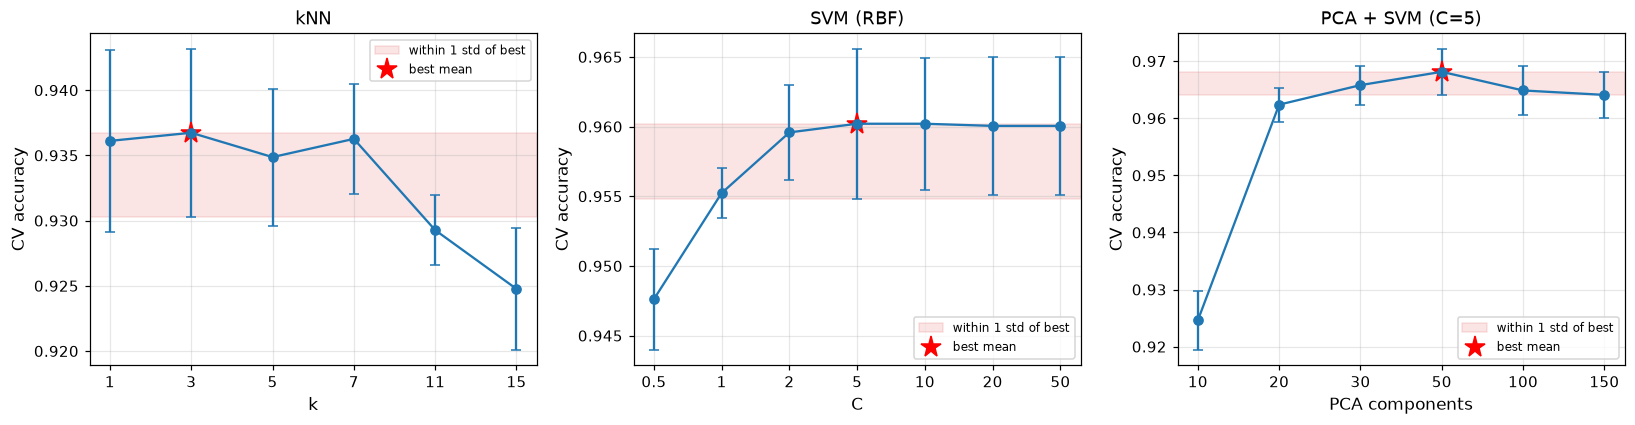

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_sweep(axes[0], knn_sweep, 'kNN', 'k')
plot_sweep(axes[1], svm_sweep, 'SVM (RBF)', 'C')
plot_sweep(axes[2], pca_sweep, f'PCA + SVM (C={best_C:g})', 'PCA components')
plt.tight_layout(); save_fig('sweeps', fig); plt.show()

**Neural-network training curves** (mean ± std over the CV folds)

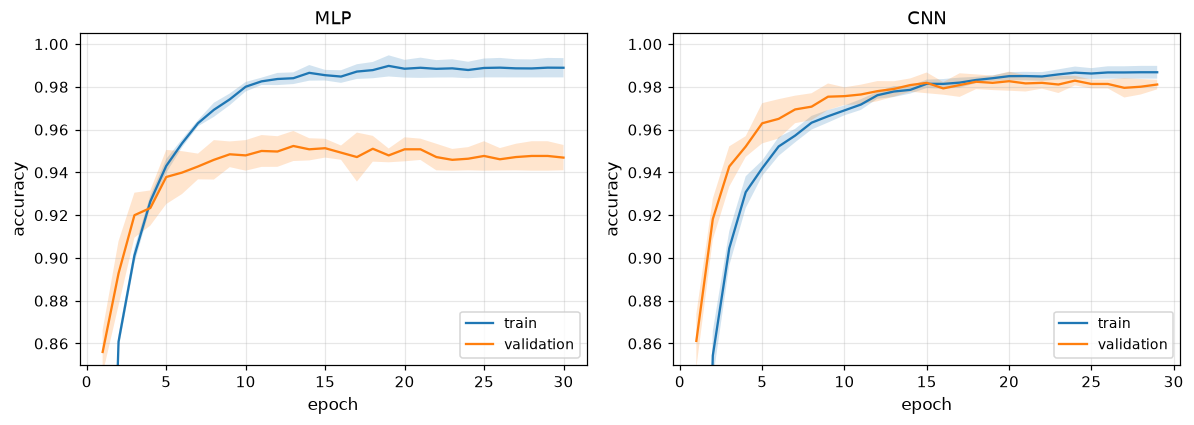

In [37]:
fig = plot_nn_curves(baseline_cv); save_fig('nn_curves', fig); plt.show()

**PCA: spectrum and components**

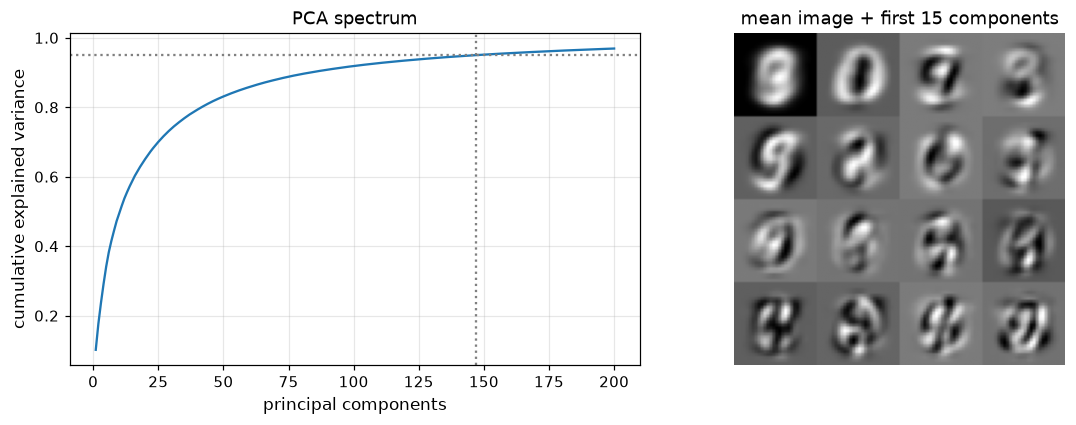

In [38]:
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(1, 2, 1); ax.plot(range(1, 201), cum[:200]); ax.grid(alpha=0.3)
ax.axhline(0.95, color='gray', ls=':'); ax.axvline(n95, color='gray', ls=':')
ax.set_xlabel('principal components'); ax.set_ylabel('cumulative explained variance'); ax.set_title('PCA spectrum')
ax = fig.add_subplot(1, 2, 2); ax.axis('off'); ax.set_title('mean image + first 15 components')
canvas = np.zeros((4 * 28, 4 * 28))
for i, t in enumerate([pca_full.mean_] + list(pca_full.components_[:15])):
    r, c = divmod(i, 4); t = np.asarray(t).reshape(28, 28)
    canvas[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = (t - t.min()) / (t.max() - t.min() + 1e-9)
ax.imshow(canvas, cmap='gray')
plt.tight_layout(); save_fig('pca', fig); plt.show()

**Autoencoder reconstructions** (test images)

The Autoencoder is clearly able to identify the and reconstruct the images well

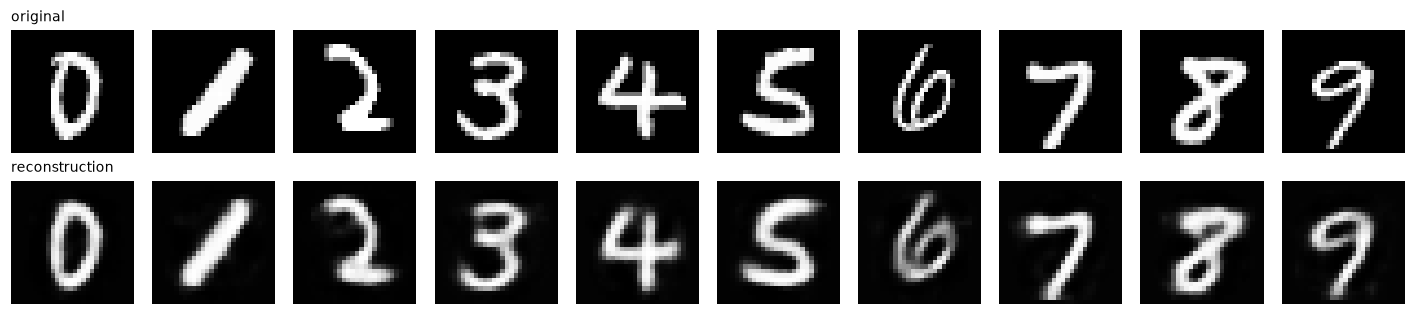

In [39]:
idx = [np.where(y_test == d)[0][0] for d in range(10)]
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for j, i in enumerate(idx):
    axes[0, j].imshow(x_test[i].reshape(28, 28), cmap='gray'); axes[0, j].axis('off')
    axes[1, j].imshow(recon[i].reshape(28, 28), cmap='gray'); axes[1, j].axis('off')
axes[0, 0].set_title('original', loc='left', fontsize=9); axes[1, 0].set_title('reconstruction', loc='left', fontsize=9)
plt.tight_layout(); save_fig('ae_reconstruction', fig); plt.show()

**Feature representations (SVM): default vs. tuned hyperparameters**

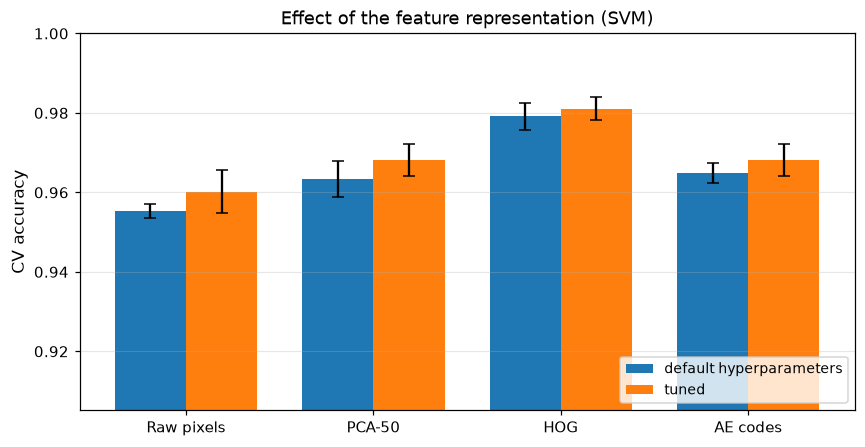

In [40]:
svm_pairs = {t: d for t, d in replaces.items() if "knn" not in t.lower()}      # tuned name -> default name
pca_label = f'PCA-{best_ncomp}' if best_ncomp == pca_default else f'PCA ({pca_default}→{best_ncomp})'
labels = ['Raw pixels', pca_label, 'HOG', 'AE codes']
d_acc = [all_cv[d]['folds']['accuracy'] for d in svm_pairs.values()]
t_acc = [all_cv[t]['folds']['accuracy'] for t in svm_pairs]

x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - w / 2, [a.mean() for a in d_acc], w, yerr=[a.std() for a in d_acc], capsize=4, label='default hyperparameters')
ax.bar(x + w / 2, [a.mean() for a in t_acc], w, yerr=[a.std() for a in t_acc], capsize=4, label='tuned')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(min(a.mean() for a in d_acc + t_acc) - 0.05, 1.0)
ax.set_ylabel('CV accuracy'); ax.set_title('Effect of the feature representation (SVM)')
ax.grid(alpha=0.3, axis='y'); ax.legend(loc='lower right')
plt.tight_layout(); save_fig('features', fig); plt.show()

**Training paradigms: accuracy vs. amount of labeled data**

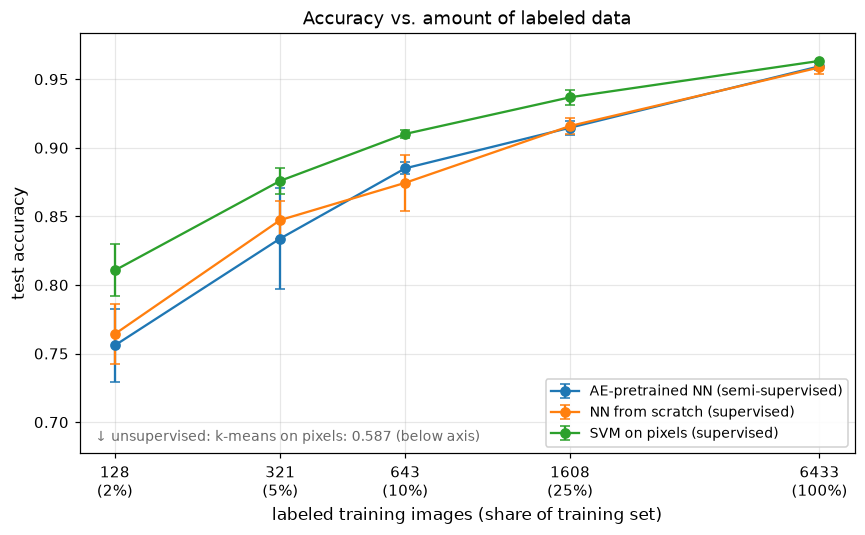

In [41]:
best_km = km_table['accuracy'].idxmax()
fig, ax = plt.subplots(figsize=(8, 5))
plot_label_sweep(semi_df, ax, hlines={f'unsupervised: k-means on {best_km}': km_table.loc[best_km, 'accuracy']})
plt.tight_layout(); save_fig('paradigms', fig); plt.show()

# 5. Testing

## 5.1 Test utils

In [ ]:
def count_params(model):
    """Number of stored numbers defining the model (NN: weights; SVM: support vectors + dual coefs;
    kNN: the stored training set; RF: tree nodes; PCA: components + mean)."""
    if hasattr(model, 'parameters'):                       # torch module or AEFeatures
        return sum(p.numel() for p in model.parameters())
    if isinstance(model, Pipeline):
        return sum(count_params(step) for _, step in model.steps)
    if isinstance(model, LogisticRegression):
        return model.coef_.size + model.intercept_.size
    if isinstance(model, SVC):
        return model.support_vectors_.size + model.dual_coef_.size + model.intercept_.size
    if isinstance(model, KNeighborsClassifier):
        return model.n_samples_fit_ * model.n_features_in_
    if isinstance(model, RandomForestClassifier):
        return sum(e.tree_.node_count for e in model.estimators_)
    if isinstance(model, PCA):
        return model.components_.size + model.mean_.size
    if isinstance(model, HOG):
        return 0
    return np.nan


def fit_and_test(name, spec, x_tr, y_tr, x_te, y_te, seed=42, inner_val_frac=0.15):
    """Refit on the full training set and evaluate ONCE on the test set."""
    model = spec['make_model']()
    t0 = time.time()
    if spec.get('kind') == 'nn':
        x_fit, x_val, y_fit, y_val = train_test_split(
            x_tr, y_tr, test_size=inner_val_frac, stratify=y_tr, random_state=seed)
        hist = model.fit(x_fit, y_fit, x_val, y_val, seed=seed, verbose=False,
                         **spec.get('fit_kwargs', {}))
    else:
        model.fit(x_tr, y_tr)
        hist = None
    fit_time = time.time() - t0
    t0 = time.time()
    y_pred = np.asarray(model.predict(x_te))
    pred_time = time.time() - t0
    row = {**evaluate(y_te, y_pred), 'fit_time_s': fit_time,
           'predict_ms_per_img': 1000 * pred_time / len(x_te), 'n_params': count_params(model)}
    return {'row': row, 'model': model, 'y_pred': y_pred, 'history': hist}

## 5.2 Final evaluation

Finalists come from the **CV leaderboard of the tuned models** (Selected HOG + SVM (tuned), KNN (tuned), CNN). Each is refitted on the full training split and evaluated once on the test split.

In [ ]:
all_specs = {**baseline_specs, **feat_specs, **tuned_specs}
ranking = list(leaderboard.index)
nn_names = [n for n, s in all_specs.items() if s['kind'] == 'nn']
best_nn = max(nn_names, key=lambda n: all_cv[n]['folds']['accuracy'].mean())
# finalists = list(dict.fromkeys(ranking[:2] + [best_nn]))  # alternatively top 2 + best NN 
finalists = list(dict.fromkeys(['CNN', 'HOG + SVM (tuned)','kNN (tuned)']))
print('finalists:', finalists)

final = {n: fit_and_test(n, all_specs[n], x_train, y_train, x_test, y_test, seed=SEED) for n in finalists}
test_table = pd.DataFrame({n: f['row'] for n, f in final.items()}).T.astype(float).sort_values('macro_f1', ascending=False)
test_table.round({'accuracy': 4, 'macro_precision': 4, 'macro_recall': 4, 'macro_f1': 4,
                  'fit_time_s': 2, 'predict_ms_per_img': 3})

finalists: ['CNN', 'HOG + SVM (tuned)', 'kNN (tuned)']


,accuracy,macro_precision,macro_recall,macro_f1,fit_time_s,predict_ms_per_img,n_params
CNN,0.9832,0.9832,0.9833,0.9832,14.57,0.017,206922.0
HOG + SVM (tuned),0.9820,0.9820,0.9819,0.9819,20.76,4.402,3629250.0
kNN (tuned),0.9323,0.9336,0.9317,0.9319,0.01,0.185,5043472.0


## 5.3 Error analysis

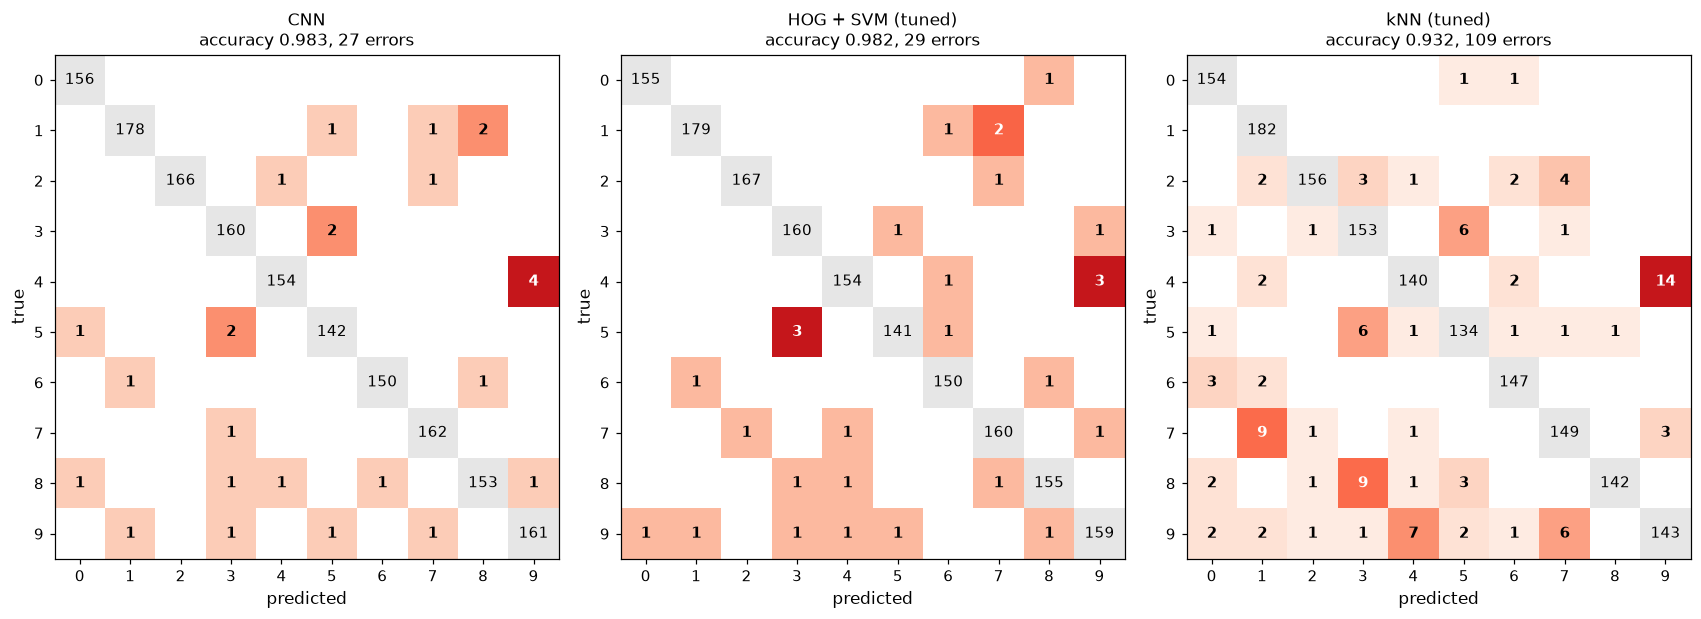

In [62]:
fig, axes = plt.subplots(1, len(final), figsize=(5.2 * len(final), 5.4), squeeze=False)
for ax, (n, f) in zip(axes[0], final.items()):
    plot_confusion(y_test, f['y_pred'], n, ax)
plt.tight_layout(); save_fig('confusion', fig); plt.show()

### ROC-AUC scores

In [76]:
def class_scores(model, X):
    """(N, 10) per-class scores: probabilities if the model has them, else SVM decision values."""
    if hasattr(model, 'predict_proba'):
        return np.asarray(model.predict_proba(X))
    return np.asarray(model.decision_function(X))

# this definition is included here and not in metrics as we wanted to compare performances on train and test sets
def macro_roc(y_true, sc, grid=np.linspace(0, 1, 500)):
    """Macro-averaged one-vs-rest ROC curve: mean TPR over the 10 classes on a common FPR grid."""
    tprs = []
    for c in range(sc.shape[1]):
        fpr, tpr, _ = roc_curve(y_true == c, sc[:, c])
        tprs.append(np.interp(grid, fpr, tpr))
    return grid, np.mean(tprs, axis=0)

In [ ]:
roc_models = ['CNN', 'HOG + SVM (tuned)', 'kNN (tuned)']
scores = {n: class_scores(final[n]['model'], x_test) for n in roc_models}      # uses the fitted finalists

def cv_scores(make_model, kind, X, y, fit_kwargs=None, n_splits=5, seed=SEED, inner_val_frac=0.15):
    """Held-out class scores for every CV fold (same folds and early-stopping protocol as cross_validate)."""
    X, y = np.asarray(X), np.asarray(y)
    out = []
    for fold, (tr, te) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y), start=1):
        model = make_model()
        if kind == 'nn':
            X_fit, X_val, y_fit, y_val = train_test_split(X[tr], y[tr], test_size=inner_val_frac,
                                                          stratify=y[tr], random_state=seed + fold)
            model.fit(X_fit, y_fit, X_val, y_val, seed=seed + fold, verbose=False, **(fit_kwargs or {}))
        else:
            model.fit(X[tr], y[tr])
        out.append((y[te], class_scores(model, X[te])))
        print(f'fold {fold}/{n_splits} done')
    return out

cv_roc = {}
for n in roc_models:
    print(n)
    spec = all_specs[n]
    cv_roc[n] = cv_scores(spec['make_model'], spec['kind'], x_train, y_train, spec.get('fit_kwargs'))

CNN
fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
HOG + SVM (tuned)
fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
kNN (tuned)
fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done


In [74]:
# Training-set scores of the fitted finalists (kNN excluded: every training image is its own nearest neighbour)
train_models = [n for n in roc_models if not n.startswith('kNN')]
train_scores = {n: class_scores(final[n]['model'], x_train) for n in train_models}

def macro_auc(y_true, sc):
    return np.mean([roc_auc_score(y_true == c, sc[:, c]) for c in range(sc.shape[1])])

def tpr_at_fpr(y_true, sc, fpr_target=0.01):
    grid, tpr = macro_roc(y_true, sc, grid=np.linspace(0, 1, 2001))
    return float(np.interp(fpr_target, grid, tpr))

# bootstrap uncertainty of the test AUC (resampling the test images)
rng = np.random.default_rng(SEED)
boot = {n: [] for n in roc_models}
for _ in range(300):
    i = rng.integers(0, len(y_test), len(y_test))
    for n in roc_models:
        boot[n].append(macro_auc(y_test[i], scores[n][i]))

rows = []
for n in roc_models:
    cv_auc = np.array([macro_auc(yt, sc) for yt, sc in cv_roc[n]])
    cv_tpr = np.array([tpr_at_fpr(yt, sc) for yt, sc in cv_roc[n]])
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    rows.append({'model': n,
                 'AUC train': macro_auc(y_train, train_scores[n]) if n in train_scores else np.nan,
                 'AUC CV (mean)': cv_auc.mean(), 'AUC CV (std)': cv_auc.std(ddof=1),
                 'AUC test': macro_auc(y_test, scores[n]), 'test 95% CI low': lo, 'test 95% CI high': hi,
                 'TPR@1%FPR CV': cv_tpr.mean(), 'TPR@1%FPR test': tpr_at_fpr(y_test, scores[n])})
consistency = pd.DataFrame(rows).set_index('model')
consistency['CV mean inside test CI'] = ((consistency['AUC CV (mean)'] >= consistency['test 95% CI low']) &
                                         (consistency['AUC CV (mean)'] <= consistency['test 95% CI high']))
consistency.round(4)

,AUC train,AUC CV (mean),AUC CV (std),AUC test,test 95% CI low,test 95% CI high,TPR@1%FPR CV,TPR@1%FPR test,CV mean inside test CI
model,,,,,,,,,
CNN,1.0,0.9996,0.0002,0.9998,0.9996,0.9999,0.9914,0.9956,False
HOG + SVM (tuned),1.0,0.9984,0.0005,0.9985,0.9976,0.9994,0.9844,0.9872,True
kNN (tuned),NaN,0.9867,0.0032,0.9884,0.9844,0.9920,0.9491,0.9461,True


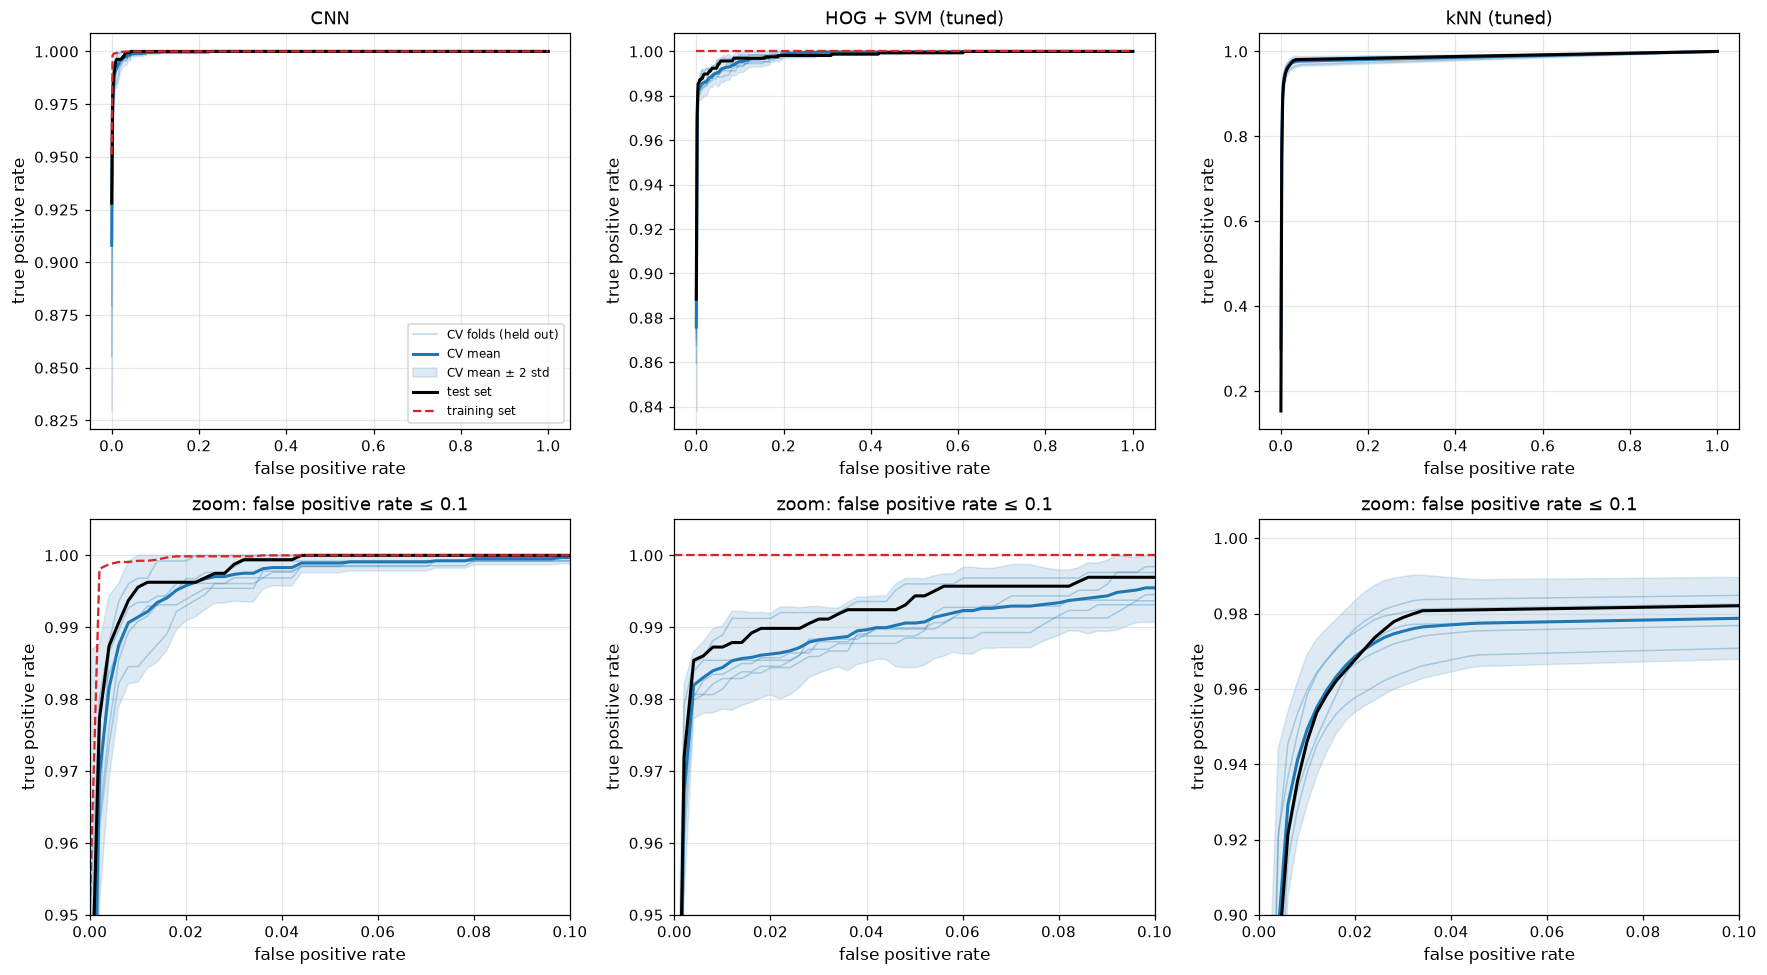

In [75]:
grid = np.linspace(0, 1, 500)
fig, axes = plt.subplots(2, len(roc_models), figsize=(5.4 * len(roc_models), 9), squeeze=False)
for j, n in enumerate(roc_models):
    fold_tprs = np.array([macro_roc(yt, sc, grid)[1] for yt, sc in cv_roc[n]])
    mean, sd = fold_tprs.mean(0), fold_tprs.std(0, ddof=1)
    tpr_test = macro_roc(y_test, scores[n], grid)[1]
    for ax in axes[:, j]:
        for k, t in enumerate(fold_tprs):
            ax.plot(grid, t, color='tab:blue', alpha=0.3, lw=1, label='CV folds (held out)' if k == 0 else None)
        ax.plot(grid, mean, color='tab:blue', lw=2, label='CV mean')
        ax.fill_between(grid, mean - 2 * sd, np.minimum(mean + 2 * sd, 1), color='tab:blue', alpha=0.15,
                        label='CV mean ± 2 std')
        ax.plot(grid, tpr_test, color='black', lw=2, label='test set')
        if n in train_scores:
            ax.plot(grid, macro_roc(y_train, train_scores[n], grid)[1], color='tab:red', ls='--', lw=1.5,
                    label='training set')
        ax.grid(alpha=0.3); ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate')
    axes[0, j].set_title(n)
    i01 = np.searchsorted(grid, 0.1)                       # zoom window adapts to the model's TPR at FPR = 0.1
    lo = min(mean[i01], tpr_test[i01]) - 0.03
    axes[1, j].set_xlim(0, 0.1); axes[1, j].set_ylim(max(0.0, np.floor(lo * 20) / 20), 1.005)
    axes[1, j].set_title('zoom: false positive rate ≤ 0.1')
axes[0, 0].legend(loc='lower right', fontsize=8)
plt.tight_layout(); save_fig('roc_consistency', fig); plt.show()

### Misclassifications

Best model on the test set: CNN
              precision    recall  f1-score   support

           0      0.987     1.000     0.994       156
           1      0.989     0.978     0.983       182
           2      1.000     0.988     0.994       168
           3      0.970     0.988     0.979       162
           4      0.987     0.975     0.981       158
           5      0.973     0.979     0.976       145
           6      0.993     0.987     0.990       152
           7      0.982     0.994     0.988       163
           8      0.981     0.968     0.975       158
           9      0.970     0.976     0.973       165

    accuracy                          0.983      1609
   macro avg      0.983     0.983     0.983      1609
weighted avg      0.983     0.983     0.983      1609



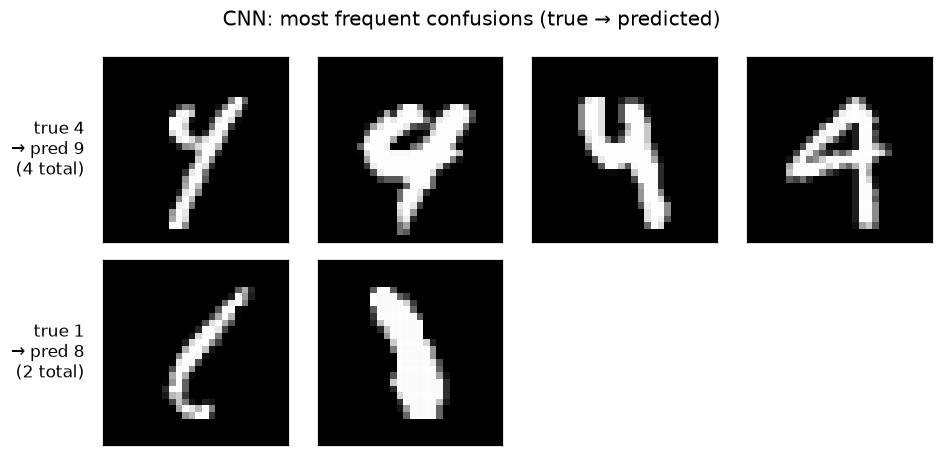

<Figure size 704x528 with 0 Axes>

In [78]:
focus = 'CNN'
# focus = test_table.index[0]
y_pred = final[focus]['y_pred']
print(f'Best model on the test set: {focus}')
print(classification_report(y_test, y_pred, digits=3))

confusions = top_confusions(y_test, y_pred)
confusions

plot_misclassified(x_test, y_test, y_pred, list(zip(confusions['true'][:2], confusions['predicted'][:4])),
                   title=f'{focus}: most frequent confusions (true → predicted)')
save_fig('misclassified_cnn')

              precision    recall  f1-score   support

           0      0.994     0.994     0.994       156
           1      0.989     0.984     0.986       182
           2      0.994     0.994     0.994       168
           3      0.970     0.988     0.979       162
           4      0.981     0.975     0.978       158
           5      0.986     0.972     0.979       145
           6      0.980     0.987     0.984       152
           7      0.976     0.982     0.979       163
           8      0.981     0.981     0.981       158
           9      0.970     0.964     0.967       165

    accuracy                          0.982      1609
   macro avg      0.982     0.982     0.982      1609
weighted avg      0.982     0.982     0.982      1609

   true  predicted  count  % of true class
0     4          9      3              1.9
1     5          3      3              2.1
2     1          7      2              1.1
3     0          8      1              0.6
4     1          6      1 

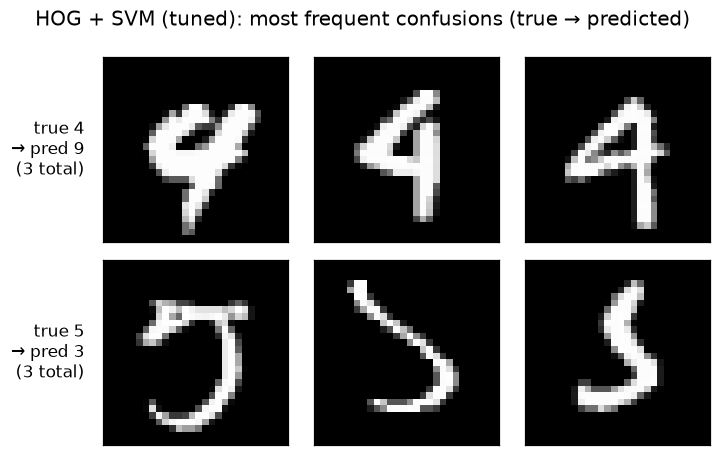

<Figure size 704x528 with 0 Axes>

In [79]:
# for HOG + SVM (tuned)
focus = 'HOG + SVM (tuned)'
y_pred = final[focus]['y_pred']
print(classification_report(y_test, y_pred, digits=3))

# For CNN
confusions = top_confusions(y_test, y_pred)
print(confusions)

plot_misclassified(x_test, y_test, y_pred, list(zip(confusions['true'][:2], confusions['predicted'][:4])),
                   title=f'{focus}: most frequent confusions (true → predicted)')
save_fig('misclassified_hog_svm')

              precision    recall  f1-score   support

           0      0.945     0.987     0.966       156
           1      0.915     1.000     0.955       182
           2      0.975     0.929     0.951       168
           3      0.890     0.944     0.916       162
           4      0.927     0.886     0.906       158
           5      0.918     0.924     0.921       145
           6      0.955     0.967     0.961       152
           7      0.925     0.914     0.920       163
           8      0.993     0.899     0.944       158
           9      0.894     0.867     0.880       165

    accuracy                          0.932      1609
   macro avg      0.934     0.932     0.932      1609
weighted avg      0.933     0.932     0.932      1609

   true  predicted  count  % of true class
0     4          9     14              8.9
1     7          1      9              5.5
2     8          3      9              5.7
3     9          4      7              4.2
4     3          5      6 

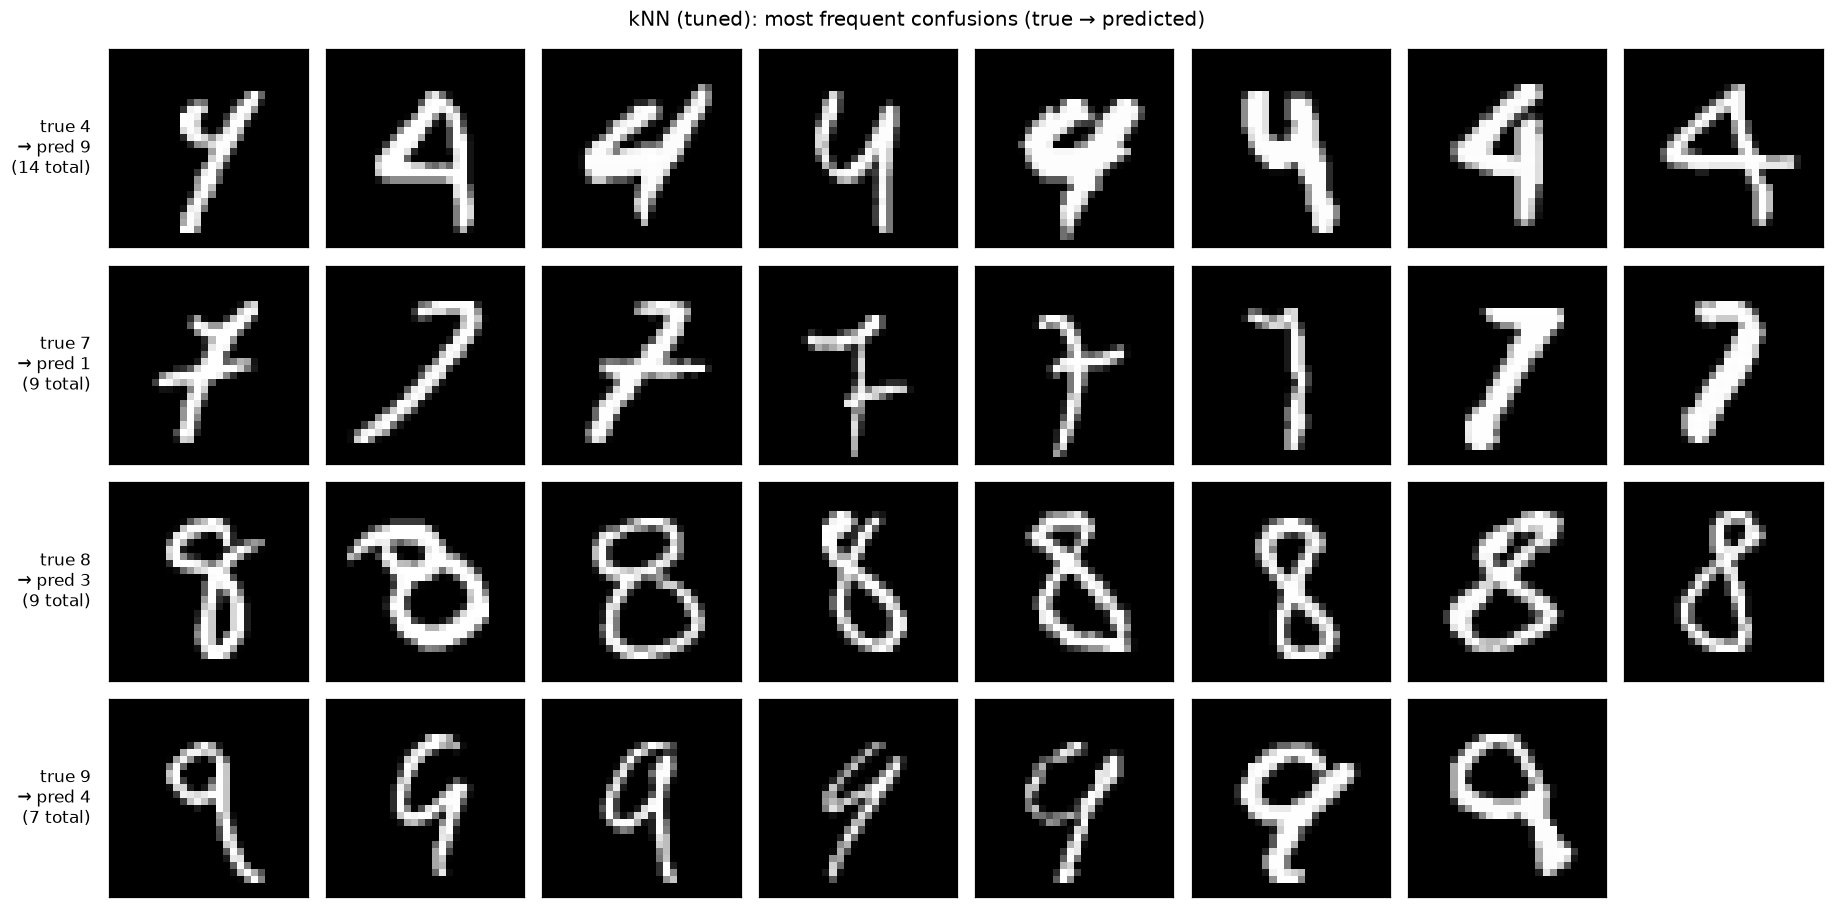

<Figure size 704x528 with 0 Axes>

In [66]:
focus = 'kNN (tuned)'
y_pred = final[focus]['y_pred']
print(classification_report(y_test, y_pred, digits=3))

confusions = top_confusions(y_test, y_pred)
print(confusions)

plot_misclassified(x_test, y_test, y_pred, list(zip(confusions['true'][:4], confusions['predicted'][:4])),
                   title=f'{focus}: most frequent confusions (true → predicted)')
save_fig('misclassified_knn')

### Summary across paradigms and representations

In [49]:
ten = semi_df[np.isclose(semi_df['label_frac'], 0.10)].groupby('method')['accuracy'].agg(['mean', 'std'])
n10 = int(semi_df.loc[np.isclose(semi_df['label_frac'], 0.10), 'n_labels'].iloc[0])
summary = pd.DataFrame([
    {'paradigm': 'supervised, all labels',                    'model': focus,               'test accuracy': test_table.loc[focus, 'accuracy']},
    {'paradigm': f'supervised, {n10} labels',                 'model': 'NN from scratch',   'test accuracy': ten.loc['NN from scratch (supervised)', 'mean']},
    {'paradigm': f'semi-supervised, {n10} labels',            'model': 'AE-pretrained NN',  'test accuracy': ten.loc['AE-pretrained NN (semi-supervised)', 'mean']},
    {'paradigm': 'unsupervised (clusters named by labels)',   'model': f'k-means on {best_km}', 'test accuracy': km_table.loc[best_km, 'accuracy']},
]).set_index('paradigm')
summary.round(4)

,model,test accuracy
paradigm,,
"supervised, all labels",HOG + SVM (tuned),0.9820
"supervised, 643 labels",NN from scratch,0.8745
"semi-supervised, 643 labels",AE-pretrained NN,0.8850
unsupervised (clusters named by labels),k-means on pixels,0.5867


# Using full 60k MNIST data

In [50]:
from torchvision import datasets, transforms

def load_digits(data_dir = './data'):
    print("Downloading and loading full MNIST dataset...")
    transform = transforms.Compose([transforms.ToTensor()])
    train_set = datasets.MNIST(root=data_dir, train=True, download=True, transform=transform)
    test_set = datasets.MNIST(root=data_dir, train=False, download=True, transform=transform)
    return train_set, test_set

MNIST dataset are flattened and scaled to be used on the models above. Again, for CNN the images are internally reshaped to 28x28.

In [ ]:
# Load full MNIST via torchvision
train_set, test_set = load_digits()

# Extract flattened arrays and scale to [0, 1]
# torchvision datasets.MNIST data is uint8 [0, 255]
X_train_full = train_set.data.numpy().reshape(-1, 28*28) / 255.0
y_train_full = train_set.targets.numpy()
X_test_full = test_set.data.numpy().reshape(-1, 28*28) / 255.0
y_test_full = test_set.targets.numpy()

print(f"Full MNIST Train shape: {X_train_full.shape}")
print(f"Full MNIST Test shape: {X_test_full.shape}")

Full MNIST Train shape: (60000, 784)
Full MNIST Test shape: (10000, 784)


The whole training data is being used (with a validation dataset being held out in case of CNN)

### CNN

In [52]:
# Create a validation split for the CNN early stopping
X_train_cnn, X_val_cnn, y_train_cnn, y_val_cnn = train_test_split(
    X_train_full, y_train_full, test_size=0.15, stratify=y_train_full, random_state=SEED
)

# Train and evaluate CNN on full MNIST
print("\n--- Training Deep CNN on Full MNIST ---")
cnn_full = CNN(p=0.3, lr=1e-3)
t0 = time.time()
cnn_full.fit(X_train_cnn, y_train_cnn, X_val=X_val_cnn, Y_val=y_val_cnn, 
             epochs=20, batch_size=64, patience=3, seed=SEED, verbose=True)
cnn_train_time = time.time() - t0

t0 = time.time()
cnn_preds = cnn_full.predict(X_test_full)
cnn_pred_time = time.time() - t0

cnn_metrics = evaluate(y_test_full, cnn_preds)
print(f"CNN Full MNIST Results:")
print(f"Accuracy: {cnn_metrics['accuracy']:.4f} | Macro F1: {cnn_metrics['macro_f1']:.4f}")


--- Training Deep CNN on Full MNIST ---
epoch   1/20  loss 0.3190  acc 0.9005  | val loss 0.0919  val acc 0.9731
epoch   2/20  loss 0.1059  acc 0.9672  | val loss 0.0587  val acc 0.9827
epoch   3/20  loss 0.0800  acc 0.9749  | val loss 0.0547  val acc 0.9850
epoch   4/20  loss 0.0664  acc 0.9796  | val loss 0.0480  val acc 0.9852
epoch   5/20  loss 0.0588  acc 0.9812  | val loss 0.0437  val acc 0.9870
epoch   6/20  loss 0.0535  acc 0.9838  | val loss 0.0395  val acc 0.9877
epoch   7/20  loss 0.0482  acc 0.9847  | val loss 0.0481  val acc 0.9862
epoch   8/20  loss 0.0479  acc 0.9848  | val loss 0.0414  val acc 0.9880
epoch   9/20  loss 0.0435  acc 0.9855  | val loss 0.0425  val acc 0.9886
epoch  10/20  loss 0.0404  acc 0.9868  | val loss 0.0384  val acc 0.9892
epoch  11/20  loss 0.0408  acc 0.9869  | val loss 0.0361  val acc 0.9899
epoch  12/20  loss 0.0388  acc 0.9878  | val loss 0.0370  val acc 0.9867
epoch  13/20  loss 0.0355  acc 0.9889  | val loss 0.0351  val acc 0.9898
epoch  14/

In [53]:
# Use the KNN model trained on subset for comparison
cnn_original = final['CNN']['model']  # already fitted on training data from earlier steps
cnn_preds_original = cnn_original.predict(X_test_full)
cnn_metrics = evaluate(y_test_full, cnn_preds_original)
print(f"Original CNN Results:")
print(f"Accuracy: {cnn_metrics['accuracy']:.4f} | Macro F1: {cnn_metrics['macro_f1']:.4f}")

Original CNN Results:
Accuracy: 0.9899 | Macro F1: 0.9898


### SVM

Generating HOG features takes a long time for full MNIST test dataset (10k images). Instead the tuned SVM is used, which performs quite well by itself on the test data.

In [54]:
results_svm_original = fit_and_test('SVM (tuned)', all_specs['SVM (tuned)'], x_train, y_train, X_test_full, y_test_full, seed=SEED)
svm_preds_original = results_svm_original['y_pred']
svm_metrics = evaluate(y_test_full, svm_preds_original)
print(f"Original SVM Results:")
print(f"Accuracy: {svm_metrics['accuracy']:.4f} | Macro F1: {svm_metrics['macro_f1']:.4f}")

Original SVM Results:
Accuracy: 0.9894 | Macro F1: 0.9892


### KNN

In [55]:
# Use the KNN model trained on subset for comparison

# fitting the KNN on the original flattened data as only the finalist models were stored
results = fit_and_test('kNN (tuned)', tuned_specs['kNN (tuned)'], x_train, y_train, X_test_full, y_test_full, seed=SEED)
knn_preds_original = results['y_pred']

knn_metrics = evaluate(y_test_full, knn_preds_original)

print(f"Original k-NN Results:")
print(f"Accuracy: {knn_metrics['accuracy']:.4f} | Macro F1: {knn_metrics['macro_f1']:.4f}")

Original k-NN Results:
Accuracy: 0.9616 | Macro F1: 0.9614


In [56]:
# Train and evaluate k-NN on full MNIST
print("\n--- Training k-NN (k=3) on Full MNIST ---")
# Using best_k = 3 from earlier hyperparameter tuning
best_k = 3
knn_full = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)

t0 = time.time()
knn_full.fit(X_train_full, y_train_full)
knn_train_time = time.time() - t0

t0 = time.time()
# k-NN prediction on 10k samples against 60k training samples
knn_preds = knn_full.predict(X_test_full)
knn_pred_time = time.time() - t0

knn_metrics = evaluate(y_test_full, knn_preds)
print(f"k-NN Full MNIST Results:")
print(f"Accuracy: {knn_metrics['accuracy']:.4f} | Macro F1: {knn_metrics['macro_f1']:.4f}")


--- Training k-NN (k=3) on Full MNIST ---
k-NN Full MNIST Results:
Accuracy: 0.9705 | Macro F1: 0.9704


###### end of file